# Livrable 3 - Captioning d'images par transfer learning

## Projet TouNum

Ce notebook construit le dernier module du projet : un réseau de neurones qui **écrit automatiquement une légende descriptive** pour une photo.

```
Images numérisées ──► Livrable 1 : photo ou autre ? ──► Livrable 2 : débruitage ──► Livrable 3 : légende
```

Les livrables 1 et 2 ont été présentés dans leurs propres notebooks. Ce livrable se concentre sur le **captioning** et le **transfer learning**. Les trois modèles sont ensuite réunis dans un notebook, qui traite automatiquement un dossier d'images inconnu, de la donnée à la légende.

## Groupe 2

1. ARMAND Chloé
2. OUBA Hamza
3. CHAOUCHE Ylies
4. FRAIOLI Enzo

**Objectif du livrable :** comparer l'architecture de captioning du workshop à une architecture que nous proposons, régler leurs hyperparamètres de la même façon, puis choisir et évaluer le modèle final sur le dataset MS COCO.

## Problématique et hypothèses

Écrire une légende demande deux compétences :

- **voir** : reconnaître les objets, les personnes et la scène sur la photo ;
- **écrire** : produire une phrase correcte qui décrit ce qui a été vu.

Le sujet impose une architecture en deux parties :

- un **CNN pré-entraîné** pour la classification (sur ImageNet) prétraite les photos et en donne une représentation compacte : c'est le **transfer learning** ;
- un **RNN** utilise cette représentation pour écrire la légende **mot par mot**.

La question étudiée est la suivante :

> Peut-on améliorer l'architecture de captioning du workshop, et quels réglages donnent les légendes les plus fidèles sur des photos jamais vues ?

**Nos hypothèses**, que nous vérifierons :

1. un CNN pré-entraîné plus précis sur ImageNet donne de meilleures caractéristiques, donc de meilleures légendes ;
2. un décodeur qui connaît le contenu global de la photo **dès le premier mot** écrit des phrases plus cohérentes ;
3. la quantité de photos d'entraînement compte davantage que les petits réglages.

Nous suivrons le protocole suivant :

1. charger MS COCO et séparer les photos en trois ensembles ;
2. préparer le texte (les légendes) ;
3. préparer les photos avec deux CNN pré-entraînés (transfer learning) ;
4. présenter l'architecture **A** (workshop) et l'architecture **B** (notre proposition) ;
5. entraîner A et B dans les mêmes conditions, puis mesurer l'effet de chaque modification de B ;
6. régler les **mêmes hyperparamètres**, de la **même façon**, dans A et dans B ;
7. entraîner les deux meilleures versions sur **20 000 photos**, puis sur **40 000 photos**, et choisir le modèle final ;
8. évaluer le modèle final sur le test, puis étudier ses réussites et ses erreurs.

## Méthode expérimentale

### Trois ensembles de photos

Le protocole est conçu pour éviter la **fuite de données** : une photo utilisée pour choisir le modèle ne sert jamais à l'évaluer.

| Ensemble | Rôle | Nombre de photos |
|---|---|---|
| **Entraînement (comparaisons)** | apprendre les poids pendant les comparaisons | 1 000 |
| **Entraînement (modèles finaux)** | apprendre les poids des modèles finaux | 20 000, puis 40 000 |
| **Validation** | comparer les modèles et choisir la meilleure époque | 1 000 |
| **Test** | mesure finale, utilisée **une seule fois** | 1 000 |

Les photos sont séparées **par photo** et non par légende : les 5 légendes d'une même photo restent dans le même ensemble. Sinon, le modèle pourrait être évalué sur une photo qu'il a déjà vue avec une autre légende.

**Pourquoi seulement 1 000 photos pour les comparaisons ?** Nous entraînons une trentaine de modèles. Avec 1 000 photos, chaque entraînement dure quelques minutes. Les écarts entre réglages sont alors **indicatifs** : c'est pourquoi le choix final entre A et B se fait sur **20 000 puis 40 000 photos**, où les résultats sont fiables.

### Comment nous mesurons la qualité

**La perte (entropie croisée)** mesure l'erreur sur le mot suivant, quand le modèle connaît la vraie légende (*teacher forcing*). C'est l'erreur que le modèle cherche à réduire : elle sert à **suivre l'apprentissage**.

**Le score BLEU** mesure la légende que le modèle écrit **seul**, comme devant le jury. Une photo n'a pas une seule bonne légende : COCO en donne 5, écrites par 5 personnes. Une accuracy « phrase exacte ou non » n'a donc pas de sens. Le BLEU compte les mots et les groupes de mots de la légende du modèle que l'on retrouve dans les 5 légendes humaines :

| Score | Ce qu'il compte | Ce qu'il nous dit |
|---|---|---|
| **BLEU-1** | les mots retrouvés | le modèle reconnaît-il les bons objets ? |
| **BLEU-4** | les suites de 1 à 4 mots retrouvées | la phrase est-elle bien construite ? |

Une pénalité réduit le score des phrases trop courtes (sinon, écrire seulement « dog » donnerait 100 %). Les scores vont de 0 à 1 : **plus c'est haut, mieux c'est**. Même un humain n'obtient pas 1, car il n'écrit jamais mot pour mot la légende d'un autre. Pour situer : l'article de référence du workshop (*Show, Attend and Tell*, Xu et al., 2015) obtient environ **0,70 en BLEU-1 et 0,24 en BLEU-4** sur COCO.

**Le critère de choix** de tous nos modèles est le **BLEU-4 de validation**, car c'est lui qui mesure la qualité de la phrase entière.

Nous utiliserons :

- TensorFlow / Keras pour les réseaux de neurones ;
- NumPy et Pandas pour les données ;
- NLTK pour le score BLEU ;
- Matplotlib pour les visualisations.

In [1]:
# Bibliothèques standard
import collections
import importlib
import json
import os
import random
import re
import shutil
import textwrap
import time
from pathlib import Path

# Calcul, tableaux et graphiques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from PIL import Image

import tensorflow as tf

# La mémoire du GPU est allouée au fur et à mesure (évite de bloquer toute la carte d'un coup)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

from tensorflow import keras

# Score BLEU
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction

print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792584987.531171   90321 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792584988.656712   90321 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792584991.754691   90321 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow : 2.22.0-rc0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Paramètres et localisation des données

Les photos et les légendes viennent de **MS COCO 2014** : environ 82 000 photos de la vie courante, avec 5 légendes en anglais chacune. C'est le dataset imposé par le sujet.

Tous les réglages communs sont regroupés ici. La graine aléatoire (`SEED`) fixe les tirages au hasard : en relançant le notebook, on obtient les mêmes ensembles de photos et les mêmes initialisations.

In [2]:
SEED = 42

# Nombre de photos par ensemble
N_TEST = 1000                # mesure finale, utilisée une seule fois
N_VAL = 1000                 # comparaison des modèles
N_TRAIN_COMPARAISON = 1000   # entraînement des comparaisons (rapide)
N_TRAIN_FINAL = 20000        # premiers modèles finaux (puis 40 000 photos en section 10.1)

# Texte
TOP_K = 5000                 # taille du vocabulaire (mots les plus fréquents), comme au workshop

# Photos passées ensemble dans le CNN pendant l'extraction (à réduire si la mémoire du GPU manque)
LOT_EXTRACTION = 16

# Entraînement
EPOCHS_MAX = 30              # nombre maximal d'époques (l'arrêt anticipé s'arrête avant)
PATIENCE = 3                 # époques sans progrès avant l'arrêt anticipé
SEUIL_SIGNIFICATIF = 0.005   # écart de BLEU-4 en dessous duquel deux réglages sont jugés équivalents

random.seed(SEED)
keras.utils.set_random_seed(SEED)

# Emplacements
COCO_DIR = Path.home() / "projet" / "workshops" / "WS6"
ANNOTATIONS = COCO_DIR / "annotations" / "captions_train2014.json"
IMAGES_DIR = COCO_DIR / "train2014"
FEATURES_DIR = Path("features")              # caractéristiques des photos calculées par les CNN
SORTIE_DIR = Path("livrable3_artifacts")     # modèle final sauvegardé
SORTIE_DIR.mkdir(exist_ok=True)

for chemin in [ANNOTATIONS, IMAGES_DIR]:
    assert chemin.exists(), f"Introuvable : {chemin}"
print("Légendes :", ANNOTATIONS)
print("Photos   :", IMAGES_DIR)

Légendes : /home/ylies/projet/workshops/WS6/annotations/captions_train2014.json
Photos   : /home/ylies/projet/workshops/WS6/train2014


## 2. Chargement des légendes et séparation des photos

Le fichier `captions_train2014.json` contient une ligne par légende, avec l'identifiant de la photo décrite. Nous regroupons les légendes **par photo**, nous gardons les photos présentes sur le disque, puis nous les mélangeons avec la graine fixe avant de les répartir dans les ensembles.

Les 1 000 photos d'entraînement des comparaisons sont **incluses** dans les 20 000 des modèles finaux, elles-mêmes incluses dans les 40 000 de la section 10.1. La validation et le test ne partagent aucune photo avec l'entraînement.

In [3]:
# Lecture du fichier de légendes
with open(ANNOTATIONS) as f:
    annotations = json.load(f)

# Regroupement des légendes par photo : {identifiant: [légende 1, légende 2, ...]}
legendes_brutes = collections.defaultdict(list)
for a in annotations["annotations"]:
    legendes_brutes[a["image_id"]].append(a["caption"])


def nom_image(image_id):
    # Le nom du fichier contient l'identifiant sur 12 chiffres
    return f"COCO_train2014_{image_id:012d}.jpg"


# Photos présentes sur le disque, mélangées avec la graine fixe
presentes = set(os.listdir(IMAGES_DIR))
ids = sorted(i for i in legendes_brutes if nom_image(i) in presentes)
random.Random(SEED).shuffle(ids)

# Séparation par photo : aucune photo n'est dans deux ensembles à la fois
ids_test = ids[:N_TEST]
ids_val = ids[N_TEST:N_TEST + N_VAL]
ids_train = ids[N_TEST + N_VAL:N_TEST + N_VAL + N_TRAIN_FINAL]
ids_train_comparaison = ids_train[:N_TRAIN_COMPARAISON]

display(pd.DataFrame({
    "photos": [len(ids_train_comparaison), len(ids_train), len(ids_val), len(ids_test)],
    "légendes": [sum(len(legendes_brutes[i]) for i in e)
                 for e in [ids_train_comparaison, ids_train, ids_val, ids_test]],
}, index=["entraînement (comparaisons)", "entraînement (modèles finaux)", "validation", "test"]))
print("Photos disponibles :", len(ids))

,photos,légendes
entraînement (comparaisons),1000,5002
entraînement (modèles finaux),20000,100054
validation,1000,5003
test,1000,5003


Photos disponibles : 82783


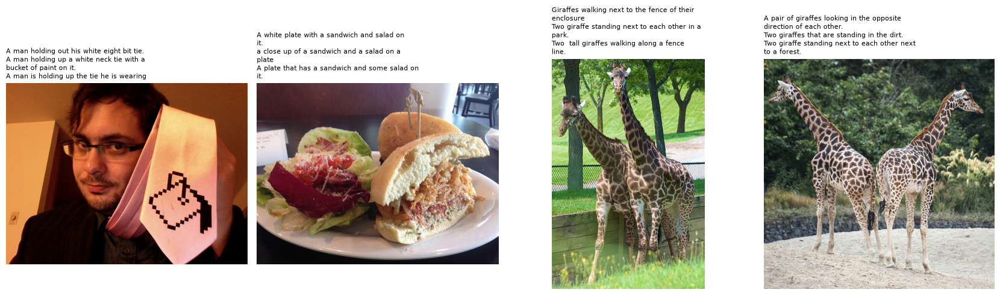

In [4]:
# Quelques photos d'entraînement avec 3 de leurs légendes
def afficher_photos(image_ids, n=4):
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 5))
    for ax, image_id in zip(axes, image_ids[:n]):
        ax.imshow(Image.open(IMAGES_DIR / nom_image(image_id)).convert("RGB"))
        texte = "\n".join(textwrap.fill(l, 45) for l in legendes_brutes[image_id][:3])
        ax.set_title(texte, fontsize=8, loc="left")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


afficher_photos(ids_train)

**Observation :** les légendes d'une même photo décrivent la même scène avec des mots et des détails différents. Il n'existe donc pas **une** bonne légende, ce qui justifie l'utilisation du score BLEU avec les 5 légendes comme références.

## 3. Prétraitement du texte

Un réseau de neurones ne manipule que des nombres. Chaque légende passe par 5 étapes, reprises du workshop *Transfer Learning* :

| Étape | Ce qui est fait | Pourquoi |
|---|---|---|
| 1. Nettoyage | minuscules, ponctuation retirée | « Dog », « dog » et « dog. » deviennent le même mot |
| 2. Balises | `<start>` au début, `<end>` à la fin | le modèle sait par quel signal commencer, et il apprend à **s'arrêter** en écrivant `<end>` |
| 3. Tokenisation | chaque mot devient un numéro ; seuls les **5 000 mots les plus fréquents** sont gardés, les autres deviennent `<unk>` | un vocabulaire limité réduit la taille du modèle ; les mots rares n'apparaissent pas assez pour être appris |
| 4. Longueur maximale | les 1 % de légendes les plus longues sont retirées | chaque mot ajouté à la longueur maximale ajoute une étape de calcul à **toutes** les légendes |
| 5. Padding | des 0 (`<pad>`) complètent les légendes jusqu'à la longueur maximale | les légendes d'un même lot doivent avoir la même longueur ; les `<pad>` sont ignorés par la perte |

Le vocabulaire est construit **uniquement sur les légendes d'entraînement** : le modèle ne doit rien connaître de la validation ni du test.

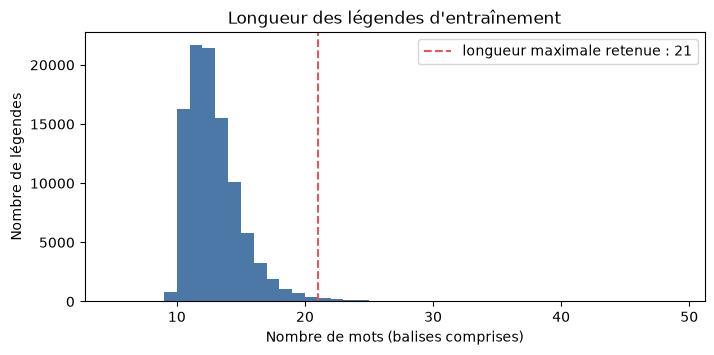

Mots différents dans l'entraînement : 12983 - vocabulaire gardé : 5000
Légendes plus longues que 21 mots : 0.8%


In [4]:
def nettoyer(texte):
    # Minuscules, puis tout ce qui n'est pas une lettre ou un chiffre devient un espace
    texte = re.sub(r"[^a-z0-9 ]", " ", texte.lower())
    return " ".join(texte.split())


# Étapes 1 et 2 : nettoyage et balises
legendes = {i: [f"<start> {nettoyer(l)} <end>" for l in legendes_brutes[i]] for i in ids}

# Étape 3 : tokenisation, sur les légendes d'entraînement uniquement
# filters="" car le texte est déjà nettoyé (et pour garder les balises < >)
tokenizer = keras.preprocessing.text.Tokenizer(num_words=TOP_K, oov_token="<unk>", filters="")
tokenizer.fit_on_texts([l for i in ids_train for l in legendes[i]])
tokenizer.word_index["<pad>"] = 0
tokenizer.index_word[0] = "<pad>"

VOCAB_SIZE = TOP_K + 1
START_ID = tokenizer.word_index["<start>"]
END_ID = tokenizer.word_index["<end>"]

# Étape 4 : longueur maximale = 99e centile des longueurs
longueurs = [len(l.split()) for i in ids_train for l in legendes[i]]
MAX_LEN = int(np.percentile(longueurs, 99))

plt.figure(figsize=(8, 3.5))
plt.hist(longueurs, bins=range(5, 50), color="#4C78A8")
plt.axvline(MAX_LEN, color="#E45756", ls="--", label=f"longueur maximale retenue : {MAX_LEN}")
plt.xlabel("Nombre de mots (balises comprises)")
plt.ylabel("Nombre de légendes")
plt.title("Longueur des légendes d'entraînement")
plt.legend()
plt.show()

print("Mots différents dans l'entraînement :", len(tokenizer.word_index), "- vocabulaire gardé :", TOP_K)
print("Légendes plus longues que", MAX_LEN, "mots :", f"{np.mean(np.array(longueurs) > MAX_LEN):.1%}")

In [5]:
# Étape 5 : numéros + padding, pour chaque photo
sequences = {}
for i in ids:
    seqs = [s for s in tokenizer.texts_to_sequences(legendes[i]) if len(s) <= MAX_LEN]
    sequences[i] = keras.preprocessing.sequence.pad_sequences(seqs, maxlen=MAX_LEN, padding="post")

# Références pour le score BLEU : les légendes humaines nettoyées, sans balises
references = {i: [nettoyer(l).split() for l in legendes_brutes[i]] for i in ids}

# Exemple complet d'une légende transformée
exemple = ids_train[0]
print("Légende :", legendes[exemple][0])
print("Numéros :", sequences[exemple][0])
print("Relu    :", " ".join(tokenizer.index_word[n] for n in sequences[exemple][0]))

Légende : <start> a man holding out his white eight bit tie <end>
Numéros : [   3    2   12   26   91   38   22 1989 1744  211    4    0    0    0
    0    0    0    0    0    0    0]
Relu    : <start> a man holding out his white eight bit tie <end> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>


### Analyse : prétraitement du texte

- **Vocabulaire :** les légendes d'entraînement contiennent **12 983 mots** différents ; nous gardons les **5 000** plus fréquents. Les mots écartés sont rares (noms propres, fautes de frappe, mots très spécialisés) : ils n'apparaissent pas assez souvent pour être appris. Les remplacer par `<unk>` divise aussi par plus de deux la taille de la dernière couche du décodeur.
- **Longueur :** la longueur maximale retenue est de **21 mots**, balises comprises. Seules **0,8 %** des légendes sont plus longues et sont retirées ; l'histogramme montre que la grande majorité est bien plus courte.
- **Vérification :** sur l'exemple, la légende devient `3 2 12 26 91 38 22 1989 1744 211 4` suivie de 0, et la relecture redonne exactement la phrase : la transformation ne perd aucune information, sauf les mots rares.
- **Volume :** les 20 000 photos des premiers modèles finaux donnent **100 054 légendes** d'entraînement, soit 5 par photo.

## 4. Prétraitement des images : le transfer learning

### Le principe

Apprendre à reconnaître des objets demande des millions de photos étiquetées. Nous n'en avons pas besoin : des CNN ont déjà été entraînés sur **ImageNet** (1,2 million de photos, 1 000 classes d'objets). Leurs couches ont appris à détecter des contours, des textures, des formes, puis des objets entiers.

Le **transfer learning** (workshop *Transfer Learning*) consiste à réutiliser ce savoir :

1. on prend un CNN pré-entraîné sur ImageNet ;
2. on retire sa dernière couche (`include_top=False`), qui choisissait l'une des 1 000 classes ;
3. on garde la **carte de caractéristiques** de sa dernière couche convolutive, qui décrit le contenu de la photo ;
4. on **gèle** le CNN (`trainable = False`) : ses poids ne changent plus.

```
Photo 299 × 299 × 3 ──► CNN pré-entraîné (gelé) ──► grille 8 × 8 × valeurs ──► 64 zones × valeurs
```

### Pourquoi garder la grille 8 × 8 plutôt qu'un seul vecteur ?

Au workshop *Transfer Learning*, `pooling='avg'` faisait la moyenne de la grille pour obtenir **un seul vecteur** par photo. Ici, nous gardons les **64 zones séparées** : chacune décrit une partie de la photo. Le mécanisme d'attention pourra ainsi choisir **quelle zone regarder** pour écrire chaque mot (le chien pour « dog », l'herbe pour « grass »).

### Pourquoi calculer les caractéristiques une seule fois ?

Le CNN étant gelé, une même photo donne toujours les mêmes caractéristiques. Nous passons donc chaque photo **une seule fois** dans le CNN et enregistrons le résultat sur le disque (fichiers `.npy`, en float16 pour diviser leur taille par deux). L'entraînement lit ensuite ces fichiers, ce qui est des dizaines de fois plus rapide que de repasser les photos dans le CNN à chaque époque. C'est aussi ce que demande le sujet : le prétraitement par le modèle pré-entraîné est fait **en amont**.

### Les deux CNN comparés

| CNN | Utilisé par | Bonnes réponses ImageNet (top-1 / top-5) | Paramètres | Profondeur | Sortie |
|---|---|---|---|---|---|
| **InceptionV3** | architecture A (workshop) | 77,9 % / 93,7 % | 23,9 M | 189 couches | 8 × 8 × 2 048 |
| **InceptionResNetV2** | architecture B | **80,3 % / 95,3 %** | 55,9 M | 449 couches | 8 × 8 × 1 536 |

*(chiffres de la documentation Keras Applications)*

InceptionResNetV2 reprend les blocs Inception d'InceptionV3 et y ajoute les **connexions résiduelles** de ResNet : chaque bloc reçoit aussi un raccourci qui recopie son entrée vers sa sortie. Ces raccourcis laissent passer le gradient pendant l'entraînement, ce qui permet d'entraîner un réseau deux fois plus profond, donc plus précis. C'est le même principe que les connexions directes du U-Net, qui avaient amélioré notre débruiteur au livrable 2.

Les deux CNN prennent des photos de **299 × 299** et donnent une grille de **8 × 8 = 64 zones** : seul le nombre de valeurs par zone change. Les deux architectures sont donc comparables sans rien modifier d'autre.

Le code des CNN, de l'encodeur, de l'attention et du décodeur est écrit dans un fichier `captioning_modele.py`. Le notebook de la soutenance réutilise **exactement le même code**, sans réentraîner. Les classes du modèle savent aussi se décrire (`get_config`) : le modèle final peut ainsi être enregistré au format `.keras` (section 13). Chaque partie est détaillée en section 5.

In [7]:
%%writefile captioning_modele.py
# =====================================================================
# captioning_modele.py
# Tout le modèle de captioning : CNN pré-entraînés (transfer learning),
# encodeur, attention, décodeur, et génération des légendes.
# Ce fichier est réutilisé tel quel par le notebook de test de la soutenance.
# =====================================================================
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# ---------------------------------------------------------------------
# 1. Transfer learning : les deux CNN pré-entraînés sur ImageNet
# ---------------------------------------------------------------------
# Pour chaque CNN : la fonction qui le crée, sa fonction de prétraitement des
# pixels et le nombre de valeurs par zone de la grille 8 x 8 en sortie.
CNNS = {
    "InceptionV3": (keras.applications.InceptionV3,
                    keras.applications.inception_v3.preprocess_input, 2048),
    "InceptionResNetV2": (keras.applications.InceptionResNetV2,
                          keras.applications.inception_resnet_v2.preprocess_input, 1536),
}


def creer_extracteur(nom_cnn):
    """CNN pré-entraîné, sans sa couche de classification, et gelé."""
    construire_cnn, _, _ = CNNS[nom_cnn]
    # include_top=False : on retire la dernière couche (les 1 000 classes d'ImageNet)
    # weights="imagenet" : on garde les poids appris sur ImageNet (transfer learning)
    # pas de pooling : on garde la grille 8 x 8 pour que l'attention puisse choisir une zone
    base = construire_cnn(include_top=False, weights="imagenet")
    base.trainable = False                       # le CNN n'est jamais réentraîné
    return keras.Model(base.input, base.output, name=f"extracteur_{nom_cnn}")


def preparer_images(images, nom_cnn):
    """Lot de photos 299 x 299 x 3 (pixels de 0 à 255) -> format attendu par le CNN."""
    _, preprocess_input, _ = CNNS[nom_cnn]
    # preprocess_input ramène les pixels entre -1 et 1, comme pendant l'entraînement sur ImageNet
    return preprocess_input(tf.cast(images, tf.float32))


def extraire_features(extracteur, images):
    """Passe les photos dans le CNN : grille 8 x 8 -> 64 zones."""
    sortie = extracteur(images, training=False)                       # (lot, 8, 8, valeurs)
    return tf.reshape(sortie, (sortie.shape[0], -1, sortie.shape[3]))  # (lot, 64, valeurs)


# ---------------------------------------------------------------------
# 2. Encodeur CNN (identique dans A et B)
# ---------------------------------------------------------------------
@keras.utils.register_keras_serializable(package="leyenda")
class CNN_Encoder(keras.Model):
    """Résume chacune des 64 zones en embedding_dim valeurs."""

    def __init__(self, embedding_dim, **kwargs):
        super().__init__(**kwargs)
        self.embedding_dim = embedding_dim
        # Une couche Dense appliquée à chaque zone séparément (les 64 zones restent séparées)
        self.fc = layers.Dense(embedding_dim)

    def call(self, x):
        x = self.fc(x)                      # (lot, 64, valeurs du CNN) -> (lot, 64, embedding_dim)
        return tf.nn.relu(x)                # ReLU : garde les valeurs positives, comme au workshop

    def get_config(self):
        # Paramètres nécessaires pour recréer l'encodeur à partir d'un fichier .keras
        return {"embedding_dim": self.embedding_dim}


# ---------------------------------------------------------------------
# 3. Attention de Bahdanau (identique dans A et B)
# ---------------------------------------------------------------------
@keras.utils.register_keras_serializable(package="leyenda")
class BahdanauAttention(keras.Model):
    """Choisit, pour chaque mot, les zones de la photo à regarder."""

    def __init__(self, units):
        super().__init__()
        self.W1 = layers.Dense(units)       # projette les zones de la photo
        self.W2 = layers.Dense(units)       # projette la mémoire du RNN
        self.V = layers.Dense(1)            # donne une note à chaque zone

    def call(self, features, hidden):
        # features : (lot, 64, embedding_dim) - hidden : mémoire du RNN (lot, units)
        hidden_with_time_axis = tf.expand_dims(hidden, 1)         # (lot, 1, units) pour l'addition
        # Mélange de « ce que montre chaque zone » et de « ce que le RNN cherche »
        attention_hidden_layer = tf.nn.tanh(self.W1(features) + self.W2(hidden_with_time_axis))
        score = self.V(attention_hidden_layer)                    # (lot, 64, 1) : une note par zone
        attention_weights = tf.nn.softmax(score, axis=1)          # notes -> pourcentages (somme = 1)
        # Contexte : moyenne des 64 zones, pondérée par les pourcentages
        context_vector = tf.reduce_sum(attention_weights * features, axis=1)   # (lot, embedding_dim)
        return context_vector, attention_weights


# ---------------------------------------------------------------------
# 4. Décodeur RNN (A : GRU + mémoire vide / B : LSTM + mémoire calculée depuis la photo)
# ---------------------------------------------------------------------
@keras.utils.register_keras_serializable(package="leyenda")
class RNN_Decoder(keras.Model):
    """Écrit la légende mot par mot."""

    def __init__(self, embedding_dim, units, vocab_size, rnn="gru", etat_initial=False, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.config_decodeur = {"embedding_dim": embedding_dim, "units": units, "vocab_size": vocab_size,
                                "rnn": rnn, "etat_initial": etat_initial, "dropout": dropout}
        self.units = units
        self.rnn = rnn
        self.etat_initial = etat_initial

        # Numéro du mot précédent -> vecteur de embedding_dim valeurs (workshop NLP)
        self.embedding = layers.Embedding(vocab_size, embedding_dim)

        # A : GRU (2 portes, 1 mémoire h) - B : LSTM (3 portes, 2 mémoires h et c)
        recurrent = layers.GRU if rnn == "gru" else layers.LSTM
        self.cellule = recurrent(units, return_sequences=True, return_state=True,
                                 recurrent_initializer="glorot_uniform")

        self.fc1 = layers.Dense(units)                  # couche intermédiaire
        self.dropout = layers.Dropout(dropout)          # hyperparamètre (0 = pas de Dropout, comme au workshop)
        self.fc2 = layers.Dense(vocab_size)             # un score par mot du vocabulaire
        self.attention = BahdanauAttention(units)

        # B uniquement : Dense qui transforment le résumé de la photo en mémoire de départ
        if etat_initial:
            self.init_h = layers.Dense(units, activation="tanh")
            if rnn == "lstm":
                self.init_c = layers.Dense(units, activation="tanh")

    def etat_depart(self, features):
        """Mémoire du RNN avant le premier mot."""
        lot = tf.shape(features)[0]
        if not self.etat_initial:
            # Architecture A (workshop) : mémoire vide
            n = 1 if self.rnn == "gru" else 2
            return [tf.zeros((lot, self.units)) for _ in range(n)]
        # Architecture B : moyenne des 64 zones = résumé de toute la photo (comme pooling='avg')
        resume = tf.reduce_mean(features, axis=1)                 # (lot, embedding_dim)
        etat = [self.init_h(resume)]
        if self.rnn == "lstm":
            etat.append(self.init_c(resume))
        return etat

    def call(self, x, features, etat, training=False):
        # x : mot précédent (lot, 1) - features : 64 zones (lot, 64, embedding_dim)
        # etat : mémoire du RNN, [h] pour le GRU, [h, c] pour le LSTM

        # 1. L'attention regarde la photo en fonction de la mémoire actuelle
        context_vector, attention_weights = self.attention(features, etat[0])

        # 2. Le mot précédent devient un vecteur
        x = self.embedding(x)                                                 # (lot, 1, embedding_dim)

        # 3. On colle le contexte de la photo et le mot
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)        # (lot, 1, 2 x embedding_dim)

        # 4. Le RNN met à jour sa mémoire en partant de la mémoire précédente
        sortie, *etat = self.cellule(x, initial_state=etat)

        # 5. Deux couches Dense donnent un score à chaque mot du vocabulaire
        y = self.fc1(sortie)
        y = tf.reshape(y, (-1, y.shape[2]))
        y = self.dropout(y, training=training)                               # actif seulement à l'entraînement
        y = self.fc2(y)                                                       # (lot, taille du vocabulaire)
        return y, etat, attention_weights


    def get_config(self):
        # Paramètres nécessaires pour recréer le décodeur à partir d'un fichier .keras
        return dict(self.config_decodeur)

    @classmethod
    def from_config(cls, config):
        modele = cls(**config)
        features = tf.zeros((1, 64, config["embedding_dim"]))
        modele(tf.zeros((1, 1), tf.int32), features, modele.etat_depart(features))   # crée les poids
        return modele


def construire(config, vocab_size):
    """Crée l'encodeur et le décodeur d'une configuration (A, B ou variante)."""
    encoder = CNN_Encoder(config["embedding_dim"])
    decoder = RNN_Decoder(config["embedding_dim"], config["units"], vocab_size,
                          config["rnn"], config["etat_initial"], config["dropout"])
    # Un premier appel sur des zéros crée tous les poids
    nb_valeurs = CNNS[config["cnn"]][2]
    features = encoder(tf.zeros((1, 64, nb_valeurs)))
    decoder(tf.zeros((1, 1), tf.int32), features, decoder.etat_depart(features))
    return encoder, decoder


# ---------------------------------------------------------------------
# 5. Génération des légendes (sans légende de référence : seulement la photo)
# ---------------------------------------------------------------------
def generer(encoder, decoder, features, start_id, max_len, mode="glouton", graine=0):
    """Écrit la légende d'un lot de photos à partir de leurs caractéristiques."""
    n = features.shape[0]
    enc = encoder(tf.cast(features, tf.float32))          # 64 zones résumées
    etat = decoder.etat_depart(enc)                       # A : zéros - B : résumé de la photo
    mot = tf.fill([n, 1], start_id)                       # on commence par <start>
    ids, attentions = [], []
    for i in range(max_len):
        logits, etat, attention = decoder(mot, enc, etat)
        if mode == "glouton":
            # Mot le plus probable
            suivant = tf.argmax(logits, axis=-1, output_type=tf.int32)
        else:
            # Tirage au hasard selon les probabilités (méthode du workshop)
            suivant = tf.cast(tf.random.stateless_categorical(logits, 1, seed=[graine, i])[:, 0], tf.int32)
        ids.append(suivant)
        attentions.append(attention[..., 0])
        mot = suivant[:, None]                            # le mot écrit devient l'entrée suivante
    return tf.stack(ids, 1).numpy(), tf.stack(attentions, 1).numpy()


def ids_vers_mots(ids, index_word, end_id):
    """Numéros -> mots, en s'arrêtant à <end> et sans les <pad>."""
    mots = []
    for i in ids:
        i = int(i)
        if i == end_id:
            break
        if i != 0:
            mots.append(index_word.get(i, "<unk>"))
    return mots

Overwriting captioning_modele.py


In [6]:
# Import du fichier qui vient d'être écrit (reload : prend en compte une éventuelle modification)
import captioning_modele as cm
importlib.reload(cm)

# Création des deux extracteurs (téléchargement des poids ImageNet la première fois)
extracteurs = {nom: cm.creer_extracteur(nom) for nom in cm.CNNS}
for nom, ext in extracteurs.items():
    print(f"{nom:18s} entrée : {ext.input_shape} - sortie : {ext.output_shape} - "
          f"paramètres gelés : {ext.count_params():,}".replace(",", " "))

I0000 00:00:1792585078.321575   90321 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5578 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


InceptionV3        entrée : (None  None  None  3) - sortie : (None  None  None  2048) - paramètres gelés : 21 802 784
InceptionResNetV2  entrée : (None  None  None  3) - sortie : (None  None  None  1536) - paramètres gelés : 54 336 736


In [7]:
def chemin_features(image_id, nom_cnn):
    # Un fichier .npy par photo et par CNN
    return FEATURES_DIR / nom_cnn / f"{image_id}.npy"


def lire_299(chemin):
    # Lecture du JPEG, conversion en RGB (3 canaux) et redimensionnement en 299 x 299
    image = tf.io.read_file(chemin)
    image = tf.image.decode_jpeg(image, channels=3)
    return tf.image.resize(image, (299, 299))


def extraire(image_ids, nom_cnn):
    # Calcule et enregistre les caractéristiques des photos qui ne le sont pas encore
    (FEATURES_DIR / nom_cnn).mkdir(parents=True, exist_ok=True)
    a_faire = [i for i in image_ids if not chemin_features(i, nom_cnn).exists()]
    if not a_faire:
        print(f"{nom_cnn} : caractéristiques déjà calculées")
        return

    # Lecture des photos en parallèle, par petits lots (InceptionResNetV2 demande beaucoup de mémoire)
    chemins = [str(IMAGES_DIR / nom_image(i)) for i in a_faire]
    lots = tf.data.Dataset.from_tensor_slices(chemins).map(lire_299, num_parallel_calls=tf.data.AUTOTUNE)
    lots = lots.batch(LOT_EXTRACTION).prefetch(2)

    debut, k = time.perf_counter(), 0
    for images in lots:
        x = cm.preparer_images(images, nom_cnn)                        # pixels entre -1 et 1
        features = cm.extraire_features(extracteurs[nom_cnn], x).numpy()   # (lot, 64, valeurs)
        for image_id, f in zip(a_faire[k:k + len(features)], features):
            np.save(chemin_features(image_id, nom_cnn), f.astype("float16"))   # un fichier par photo
        k += len(features)
    print(f"{nom_cnn} : {len(a_faire)} photos en {time.perf_counter() - debut:.0f} s")


# Réutilisation des caractéristiques InceptionV3 de notre premier essai, si elles existent
ancien = FEATURES_DIR / "propre"
if ancien.exists() and not (FEATURES_DIR / "InceptionV3").exists():
    ancien.rename(FEATURES_DIR / "InceptionV3")

# Extraction pour toutes les photos utilisées, avec les deux CNN
for nom_cnn in cm.CNNS:
    extraire(ids_train + ids_val + ids_test, nom_cnn)

for nom_cnn in cm.CNNS:
    print(nom_cnn, ": forme des caractéristiques d'une photo =", np.load(chemin_features(ids_train[0], nom_cnn)).shape)

InceptionV3 : caractéristiques déjà calculées
InceptionResNetV2 : caractéristiques déjà calculées
InceptionV3 : forme des caractéristiques d'une photo = (64, 2048)
InceptionResNetV2 : forme des caractéristiques d'une photo = (64, 1536)


### Analyse : prétraitement des images

- **Même grille pour les deux CNN :** chaque photo devient **64 zones**, de 2 048 valeurs avec InceptionV3 et de 1 536 valeurs avec InceptionResNetV2. Seule la taille des zones change : l'encodeur les ramène à la même taille, et le reste du modèle est identique pour A et B.
- **Transfer learning :** les **21,8 millions** de paramètres d'InceptionV3 et les **54,3 millions** d'InceptionResNetV2 restent gelés. Seuls l'encodeur et le décodeur sont entraînés (6,6 à 9,3 millions de paramètres selon la configuration).
- **Calcul en amont indispensable :** InceptionResNetV2 a mis **1 102 s (environ 18 min) pour 20 000 photos** (section 10.1). Refaire ce calcul à chaque époque multiplierait la durée de chaque entraînement ; lire les fichiers `.npy` ne prend que quelques secondes.

## 5. Les deux architectures

### 5.1 Architecture A : le modèle du workshop

L'architecture A est celle du workshop *Captioning*, inspirée de l'article *Show, Attend and Tell* (Xu et al., 2015). Elle a trois parties :

| Partie | Couches | Rôle | Entraînée ? |
|---|---|---|---|
| **CNN pré-entraîné** | InceptionV3 | **voir** : décrire chacune des 64 zones de la photo | non (gelé) |
| **Encodeur** | Dense(256) + ReLU | **résumer** chaque zone en 256 valeurs | oui |
| **Décodeur** | Embedding, attention de Bahdanau, GRU 512, Dense 512, Dense 5 001 | **écrire** la légende mot par mot | oui |

**L'encodeur** applique la même couche Dense à chacune des 64 zones. Il ne les aplatit pas en un seul vecteur, pour que l'attention puisse encore choisir entre elles.

**Le décodeur** écrit un mot à la fois. Il part de `<start>` et, à chaque étape :

1. l'**attention de Bahdanau** compare la mémoire du GRU (ce qui a déjà été écrit) à chacune des 64 zones. Elle donne une note à chaque zone, transforme les notes en pourcentages (softmax), puis calcule la moyenne des zones pondérée par ces pourcentages : c'est le **contexte**, la partie de la photo utile pour le mot suivant ;
2. l'**Embedding** transforme le mot précédent en un vecteur de 256 valeurs (workshop *NLP RNN*) ;
3. le contexte et le mot sont **collés** (256 + 256 = 512 valeurs) et entrent dans le **GRU**, qui met à jour sa mémoire ;
4. deux couches **Dense** donnent un score à chacun des 5 001 mots du vocabulaire : le meilleur devient le mot suivant.

Le mot écrit devient l'entrée de l'étape suivante, jusqu'à ce que le modèle écrive `<end>`.

**Avant le premier mot**, la mémoire du GRU est **remplie de zéros** : le décodeur ne sait encore rien de la photo, seule l'attention la regarde.

**Correction du code du workshop :** dans le code d'origine, le GRU recevait le mot et le contexte, mais **pas sa mémoire de l'étape précédente** (`self.gru(x)` au lieu de `self.gru(x, initial_state=...)`). Il repartait donc de zéro à chaque mot, et seule l'attention utilisait la mémoire. Nous transmettons la mémoire au RNN dans **les deux** architectures : c'est le fonctionnement normal d'un RNN, qui garde ainsi le fil de la phrase.

### 5.2 Architecture B : notre proposition

Pour construire B, nous sommes partis des **défauts observés** sur A lors d'un premier essai (5 000 photos d'entraînement), puis nous avons cherché, dans les workshops et dans l'article de référence, une solution pour chacun. B reprend l'architecture **d'origine de l'article**, que le workshop avait simplifiée, avec un CNN plus récent.

| | Architecture A (workshop) | Architecture B (notre proposition) |
|---|---|---|
| CNN pré-entraîné | InceptionV3 | **InceptionResNetV2** |
| Encodeur | Dense 256 + ReLU | Dense 256 + ReLU |
| Attention | Bahdanau | Bahdanau |
| RNN | GRU 512 | **LSTM 512** |
| Mémoire de départ | zéros | **calculée depuis la photo** |

#### Modification 1 : InceptionV3 → InceptionResNetV2

- **Défaut observé :** dans nos moins bonnes légendes, le modèle se trompait d'**objet**. Il écrivait « a dog walking down a street » pour des pigeons sur une fenêtre, ou « a man sitting on a bench with a dog » pour une moto bâchée. La phrase était correcte, mais elle décrivait un objet mal reconnu.
- **Explication :** le décodeur ne voit jamais la photo, seulement les caractéristiques données par le CNN. Si le CNN reconnaît mal un objet, aucun réglage du décodeur ne peut le corriger.
- **Solution :** un CNN plus précis sur ImageNet (80,3 % contre 77,9 %), qui garde la même entrée et la même grille de 64 zones (section 4).
- **Ce que nous mesurerons :** le BLEU-1, qui compte les mots justes, donc les objets reconnus.

#### Modification 2 : GRU → LSTM

- **Défaut observé :** nos légendes ratées commençaient bien puis **dérivaient** en fin de phrase (« a dog is laying » … « on a green ground »).
- **Explication :** le GRU n'a qu'une mémoire. Le LSTM (workshop *NLP RNN*) a **deux mémoires** : `h` (court terme) et `c` (long terme), cette dernière étant protégée par une porte d'oubli. Il garde plus facilement le sujet de la phrase jusqu'au bout.
- **Source :** l'article *Show, Attend and Tell* utilise un LSTM ; le workshop l'a remplacé par un GRU pour simplifier.
- **Ce que nous mesurerons :** le BLEU-4, qui mesure la construction de la phrase.
- **À noter :** lors de notre premier essai, le LSTM seul faisait **jeu égal** avec le GRU. Son intérêt principal est de recevoir **deux** mémoires de départ calculées depuis la photo (modification 3).

#### Modification 3 : mémoire de départ calculée depuis la photo

- **Défaut observé :** dans A, la mémoire part de zéro. Le premier mot est choisi presque sans information, et nos cartes d'attention montraient qu'après quelques mots l'attention **se fige** sur les mêmes zones : le décodeur n'a pas de vue d'ensemble de la scène.
- **Solution :** avant le premier mot, nous faisons la **moyenne des 64 zones** (un résumé de toute la photo, comme le `pooling='avg'` du workshop *Transfer Learning*), puis une couche **Dense** la transforme en mémoire de départ `h₀` (et `c₀` pour le LSTM).
- **Sources :** c'est la méthode de l'article, et c'est le principe de la *Dense Map* présentée dans le schéma d'introduction du workshop *Captioning* (« cette représentation est mise en entrée comme état caché initial aux cellules du RNN »), que le code du workshop n'implémentait pas.
- **Les deux informations se complètent :** la mémoire de départ donne la **vue d'ensemble** (« une scène de rue »), l'attention donne le **détail** à chaque mot (« ici, un bus »).
- **Coût :** deux couches Dense (environ 0,26 million de paramètres, moins de 4 % du modèle).

Ce résumé est calculé à partir de la **photo seule**. Les légendes ne servent qu'à l'entraînement et au calcul du score : le modèle n'en a pas besoin pour légender une photo inconnue.

#### Pourquoi changer trois éléments à la fois ?

Les trois modifications forment un tout cohérent : un **meilleur CNN** donne de meilleures caractéristiques, la **mémoire de départ** transmet une vue d'ensemble de ces caractéristiques au décodeur, et le **LSTM** garde cette information jusqu'à la fin de la phrase. Pour savoir ce que chacune apporte, nous les testons aussi **une par une** sur A (section 8).

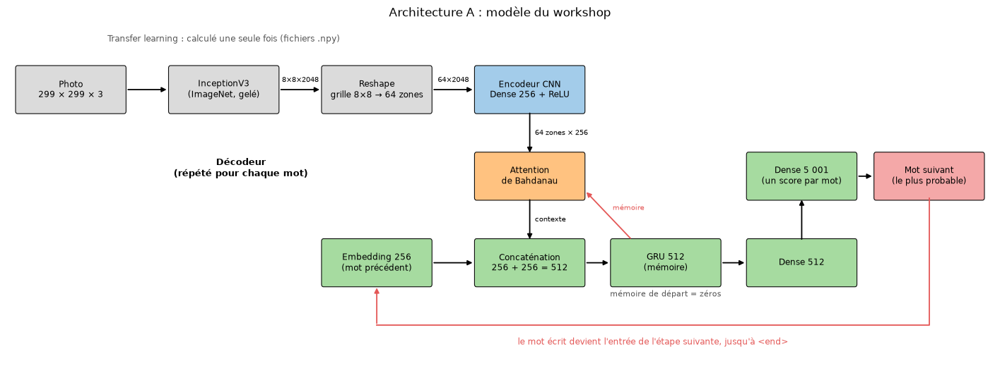

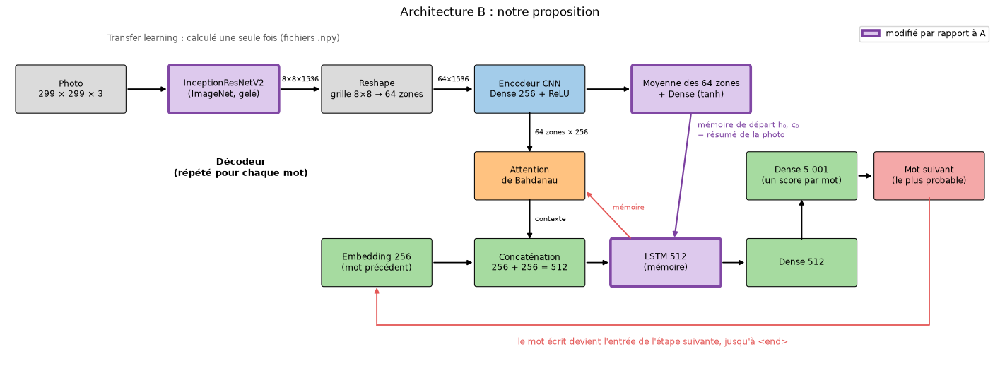

In [10]:
# ---------- Schéma des deux architectures ----------
def boite(ax, x, y, texte, couleur, modifie=False, l=2.1, h=0.9):
    # Une couche = une boîte ; les couches modifiées dans B ont un contour épais violet
    ax.add_patch(FancyBboxPatch((x - l / 2, y - h / 2), l, h, boxstyle="round,pad=0.05",
                                fc=couleur, ec="#7B3FA0" if modifie else "black",
                                lw=2.6 if modifie else 0.8, alpha=0.95))
    ax.text(x, y, texte, ha="center", va="center", fontsize=8.5)


def fleche(ax, depart, arrivee, texte="", couleur="black", rad=0.0):
    ax.annotate("", xy=arrivee, xytext=depart,
                arrowprops=dict(arrowstyle="-|>", color=couleur, lw=1.3, connectionstyle=f"arc3,rad={rad}"))
    if texte:
        vertical = abs(depart[0] - arrivee[0]) < 0.6
        x = (depart[0] + arrivee[0]) / 2 + (0.12 if vertical else 0)
        y = (depart[1] + arrivee[1]) / 2 + (0 if vertical else 0.2)
        ax.text(x, y, texte, ha="left" if vertical else "center", va="center", fontsize=7.5, color=couleur)


def schema_architecture(titre, cnn, valeurs, rnn, etat_initial):
    GRIS, BLEU, ORANGE, VERT, ROUGE, VIOLET = "#d9d9d9", "#9ecae9", "#ffbf79", "#a1d99b", "#f4a3a3", "#dcc6ec"
    B = etat_initial
    fig, ax = plt.subplots(figsize=(18, 6.2))

    # Ligne du haut : transfer learning, fait une seule fois
    boite(ax, 0, 4, "Photo\n299 × 299 × 3", GRIS, l=2.5)
    boite(ax, 3.6, 4, f"{cnn}\n(ImageNet, gelé)", VIOLET if B else GRIS, modifie=B, l=2.5)
    boite(ax, 7.2, 4, "Reshape\ngrille 8×8 → 64 zones", GRIS, l=2.5)
    boite(ax, 10.8, 4, "Encodeur CNN\nDense 256 + ReLU", BLEU, l=2.5)
    fleche(ax, (1.3, 4), (2.3, 4))
    fleche(ax, (4.9, 4), (5.9, 4), f"8×8×{valeurs}")
    fleche(ax, (8.5, 4), (9.5, 4), f"64×{valeurs}")
    ax.text(3.6, 5.0, "Transfer learning : calculé une seule fois (fichiers .npy)",
            ha="center", fontsize=8.5, color="#555555")

    # Décodeur : répété pour chaque mot
    boite(ax, 10.8, 2.2, "Attention\nde Bahdanau", ORANGE, l=2.5)
    boite(ax, 7.2, 0.4, "Embedding 256\n(mot précédent)", VERT, l=2.5)
    boite(ax, 10.8, 0.4, "Concaténation\n256 + 256 = 512", VERT, l=2.5)
    boite(ax, 14.0, 0.4, f"{rnn} 512\n(mémoire)", VIOLET if B else VERT, modifie=B, l=2.5)
    boite(ax, 17.2, 0.4, "Dense 512", VERT, l=2.5)
    boite(ax, 17.2, 2.2, "Dense 5 001\n(un score par mot)", VERT, l=2.5)
    boite(ax, 20.2, 2.2, "Mot suivant\n(le plus probable)", ROUGE, l=2.5)

    fleche(ax, (10.8, 3.55), (10.8, 2.65), "64 zones × 256")
    fleche(ax, (10.8, 1.75), (10.8, 0.85), "contexte")
    fleche(ax, (8.5, 0.4), (9.5, 0.4))
    fleche(ax, (12.1, 0.4), (12.7, 0.4))
    fleche(ax, (15.3, 0.4), (15.9, 0.4))
    fleche(ax, (17.2, 0.85), (17.2, 1.75))
    fleche(ax, (18.5, 2.2), (18.9, 2.2))
    # La mémoire du RNN guide l'attention au mot suivant
    ax.annotate("", xy=(12.1, 1.9), xytext=(13.2, 0.88), arrowprops=dict(arrowstyle="-|>", color="#E45756", lw=1.3))
    ax.text(12.75, 1.5, "mémoire", ha="left", fontsize=7.5, color="#E45756")
    # Boucle : le mot écrit redevient l'entrée suivante
    ax.plot([20.2, 20.2, 7.2], [1.75, -0.9, -0.9], color="#E45756", lw=1.3)
    ax.annotate("", xy=(7.2, -0.08), xytext=(7.2, -0.9), arrowprops=dict(arrowstyle="-|>", color="#E45756", lw=1.3))
    ax.text(13.7, -1.3, "le mot écrit devient l'entrée de l'étape suivante, jusqu'à <end>",
            ha="center", fontsize=8.5, color="#E45756")
    ax.text(4.0, 2.2, "Décodeur\n(répété pour chaque mot)", ha="center", fontsize=9.5, fontweight="bold")

    # Mémoire de départ du RNN
    if B:
        boite(ax, 14.6, 4, "Moyenne des 64 zones\n+ Dense (tanh)", VIOLET, modifie=True, l=2.7)
        fleche(ax, (12.1, 4), (13.2, 4))
        ax.annotate("", xy=(14.2, 0.88), xytext=(14.6, 3.52), arrowprops=dict(arrowstyle="-|>", color="#7B3FA0", lw=1.6))
        ax.text(14.75, 3.0, "mémoire de départ h₀, c₀\n= résumé de la photo", ha="left", fontsize=8, color="#7B3FA0")
        ax.legend(handles=[Patch(fc=VIOLET, ec="#7B3FA0", lw=2.6, label="modifié par rapport à A")],
                  loc="upper right", fontsize=8.5)
    else:
        ax.text(14.0, -0.3, "mémoire de départ = zéros", ha="center", fontsize=8, color="#555555")

    ax.set_xlim(-1.5, 21.7)
    ax.set_ylim(-1.6, 5.4)
    ax.axis("off")
    ax.set_title(titre, fontsize=12)
    plt.show()


schema_architecture("Architecture A : modèle du workshop", "InceptionV3", 2048, "GRU", False)
schema_architecture("Architecture B : notre proposition", "InceptionResNetV2", 1536, "LSTM", True)

### 5.3 Les configurations

Une **configuration** regroupe tous les choix d'un modèle : l'architecture (CNN, RNN, mémoire de départ) et les hyperparamètres (tailles, Dropout, taux d'apprentissage, taille des lots). Les valeurs de départ sont celles du workshop, pour A comme pour B.

In [11]:
# Hyperparamètres de départ : valeurs du workshop, identiques pour A et B
HYPERPARAMETRES_WORKSHOP = {
    "units": 512,          # taille de la mémoire du RNN et de l'attention
    "embedding_dim": 256,  # taille des vecteurs de mots et des zones après l'encodeur
    "dropout": 0.0,        # pas de Dropout dans le workshop
    "lr": 0.001,           # taux d'apprentissage d'Adam (valeur par défaut)
    "batch_size": 64,      # nombre de légendes par lot
}

CONFIG_A = {"cnn": "InceptionV3", "rnn": "gru", "etat_initial": False, **HYPERPARAMETRES_WORKSHOP}
CONFIG_B = {"cnn": "InceptionResNetV2", "rnn": "lstm", "etat_initial": True, **HYPERPARAMETRES_WORKSHOP}

# Nombre de paramètres entraînables de chaque architecture (le CNN gelé n'est pas compté)
for nom, config in [("A", CONFIG_A), ("B", CONFIG_B)]:
    encoder, decoder = cm.construire(config, VOCAB_SIZE)
    print(f"Architecture {nom} : encodeur {encoder.count_params():,} + décodeur {decoder.count_params():,} "
          f"= {encoder.count_params() + decoder.count_params():,} paramètres".replace(",", " "))

# Vérification des formes sur 4 photos avec l'architecture B
features = tf.constant(np.stack([np.load(chemin_features(i, "InceptionResNetV2")) for i in ids_train[:4]]), tf.float32)
enc = encoder(features)
etat = decoder.etat_depart(enc)
scores, etat, attention = decoder(tf.fill([4, 1], START_ID), enc, etat)
print("Zones après l'encodeur :", enc.shape, "- mémoires de départ :", [e.shape for e in etat])
print("Scores des mots :", scores.shape, "- poids d'attention :", attention.shape)

Architecture A : encodeur 524 544 + décodeur 6 079 114 = 6 603 658 paramètres
Architecture B : encodeur 393 472 + décodeur 6 865 546 = 7 259 018 paramètres
Zones après l'encodeur : (4, 64, 256) - mémoires de départ : [TensorShape([4, 512]), TensorShape([4, 512])]
Scores des mots : (4, 5001) - poids d'attention : (4, 64, 1)


## 6. Méthode d'entraînement

Tous les modèles de ce notebook sont entraînés par **la même fonction**, avec la même graine aléatoire. Seule la configuration change : les comparaisons sont donc équitables.

### Les données

Chaque exemple est une paire (caractéristiques de la photo, légende). Les caractéristiques sont lues sur le disque, puis les paires sont **mélangées** et regroupées **par lots** (`batch_size`). Une photo apparaît 5 fois par époque, une fois par légende.

### Une étape d'entraînement (`train_step`)

1. l'encodeur résume les 64 zones de la photo ;
2. le décodeur reçoit sa mémoire de départ (zéros pour A, résumé de la photo pour B) et le mot `<start>` ;
3. pour chaque position de la légende, il prédit le mot suivant, et l'on calcule l'erreur avec le vrai mot ;
4. à l'étape suivante, il reçoit le **vrai** mot, et non celui qu'il a prédit : c'est le **teacher forcing**. Une erreur en début de phrase ne fausse pas ainsi tout l'apprentissage de la suite ;
5. l'erreur est moyennée sur la phrase, en ignorant les `<pad>` grâce à un **masque** ;
6. la **rétropropagation** calcule les gradients, et l'optimiseur **Adam** corrige les poids de l'encodeur et du décodeur (le CNN reste gelé).

### La fonction de perte

**L'entropie croisée** (`SparseCategoricalCrossentropy`) compare les scores des 5 001 mots au vrai mot. Elle est faible quand le modèle donne une forte probabilité au bon mot. C'est la perte du workshop, adaptée à un choix parmi un grand nombre de classes.

### Le suivi et l'arrêt anticipé

À la fin de chaque époque, nous mesurons sur la **validation** :

- la **perte de validation**, calculée comme celle d'entraînement ;
- le **BLEU-4**, avec des légendes écrites **seules** par le modèle (mot le plus probable à chaque étape).

Lors de notre premier essai, le modèle commençait à **apprendre par cœur** après 4 à 6 époques : la perte d'entraînement continuait de baisser, mais la perte de validation remontait et le BLEU-4 baissait. L'entraînement s'arrête donc quand le **BLEU-4 de validation** ne progresse plus pendant **3 époques** (*early stopping*), et nous gardons les poids de **la meilleure époque**. Nous suivons le BLEU-4 plutôt que la perte, car c'est la qualité des phrases écrites qui nous intéresse.

### Le contrôle du surapprentissage

À la fin, nous calculons aussi le BLEU-4 sur des photos d'**entraînement**. Un grand écart entre entraînement et validation signale que le modèle a appris ses photos par cœur.

In [8]:
def dataset_entrainement(image_ids, nom_cnn, batch_size):
    # Une paire (chemin des caractéristiques, légende) par légende
    chemins, cibles = [], []
    for i in image_ids:
        for s in sequences[i]:
            chemins.append(str(chemin_features(i, nom_cnn)))
            cibles.append(s)

    def charger(chemin, cible):
        # Lecture du fichier .npy de la photo (float16 -> float32)
        return np.load(chemin.decode()).astype("float32"), cible

    nb_valeurs = cm.CNNS[nom_cnn][2]

    def mettre_en_forme(f, c):
        # tf.numpy_function perd les formes : on les redonne
        f.set_shape((64, nb_valeurs))
        c.set_shape((MAX_LEN,))
        return f, c

    ds = tf.data.Dataset.from_tensor_slices((chemins, np.array(cibles, dtype="int32")))
    ds = ds.shuffle(len(cibles), seed=SEED)          # mélange (différent à chaque époque)
    ds = ds.map(lambda p, c: tf.numpy_function(charger, [p, c], [tf.float32, tf.int32]),
                num_parallel_calls=tf.data.AUTOTUNE)  # lecture en parallèle
    ds = ds.map(mettre_en_forme)
    # drop_remainder : tous les lots ont la même taille (évite de recompiler train_step)
    return ds.batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE), len(cibles)


def charger_features(image_ids, nom_cnn):
    return np.stack([np.load(chemin_features(i, nom_cnn)) for i in image_ids])


# Caractéristiques de validation gardées en mémoire, pour chaque CNN
VAL = {nom: charger_features(ids_val, nom) for nom in cm.CNNS}
# Paires (numéro de la photo, légende) de validation, pour la perte de validation
val_cibles = [(k, s) for k, i in enumerate(ids_val) for s in sequences[i]]

# Perte du workshop : entropie croisée, sans compter les <pad> (masque)
loss_object = keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")


def loss_function(real, pred):
    mask = tf.cast(tf.math.not_equal(real, 0), tf.float32)     # 0 = <pad> : ignoré
    return tf.reduce_mean(loss_object(real, pred) * mask)


def bleu(hypotheses, image_ids):
    # Score BLEU-1 à BLEU-4 sur tout un ensemble de photos (corpus_bleu)
    # Le lissage évite un score nul quand aucun groupe de 4 mots n'est retrouvé
    sm = SmoothingFunction().method1
    refs = [references[i] for i in image_ids]
    return {f"BLEU-{n}": corpus_bleu(refs, hypotheses, weights=tuple([1 / n] * n), smoothing_function=sm)
            for n in (1, 2, 3, 4)}


def legender(modele, features, mode="glouton", taille_lot=250):
    # Écrit les légendes d'un ensemble de photos, par lots de 250
    hypotheses, attentions = [], []
    for k in range(0, len(features), taille_lot):
        ids_mots, att = cm.generer(modele["encoder"], modele["decoder"], features[k:k + taille_lot],
                                   START_ID, MAX_LEN, mode, graine=k)
        hypotheses += [cm.ids_vers_mots(r, tokenizer.index_word, END_ID) for r in ids_mots]
        attentions.append(att)
    return hypotheses, np.concatenate(attentions)


def evaluer(modele, image_ids, features, mode="glouton"):
    hypotheses, _ = legender(modele, features, mode)
    return bleu(hypotheses, image_ids)

In [9]:
RESULTATS = {}     # tous les modèles entraînés : poids, configuration, courbes et scores


def entrainer(nom, config, image_ids):
    print(f"--- Entraînement : {nom} ---")
    keras.utils.set_random_seed(SEED)                  # même initialisation pour tous les modèles
    encoder, decoder = cm.construire(config, VOCAB_SIZE)
    optimizer = keras.optimizers.Adam(learning_rate=config["lr"])
    ds, n_legendes = dataset_entrainement(image_ids, config["cnn"], config["batch_size"])

    def perte_lot(img_tensor, target, training):
        # Perte moyenne d'un lot, avec teacher forcing
        loss = 0.0
        features = encoder(img_tensor)                             # 64 zones résumées
        etat = decoder.etat_depart(features)                       # A : zéros - B : résumé de la photo
        dec_input = tf.expand_dims(tf.fill([tf.shape(target)[0]], START_ID), 1)   # <start>
        for i in range(1, MAX_LEN):
            predictions, etat, _ = decoder(dec_input, features, etat, training=training)
            loss += loss_function(target[:, i], predictions)       # erreur sur le mot i
            dec_input = tf.expand_dims(target[:, i], 1)             # le vrai mot (teacher forcing)
        return loss / (MAX_LEN - 1)

    @tf.function(reduce_retracing=True)
    def train_step(img_tensor, target):
        with tf.GradientTape() as tape:                            # enregistre les calculs pour le gradient
            loss = perte_lot(img_tensor, target, training=True)
        variables = encoder.trainable_variables + decoder.trainable_variables
        optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
        return loss

    @tf.function(reduce_retracing=True)
    def val_step(img_tensor, target):
        return perte_lot(img_tensor, target, training=False)       # pas de mise à jour des poids

    modele = {"encoder": encoder, "decoder": decoder}
    historique = {"loss": [], "val_loss": [], "bleu4_val": []}
    meilleur, poids, attente = -1.0, None, 0
    debut = time.perf_counter()

    for epoch in range(EPOCHS_MAX):
        t = time.perf_counter()
        # 1. Entraînement sur tous les lots
        pertes = [train_step(img, cible).numpy() for img, cible in ds]

        # 2. Perte de validation
        pertes_val = []
        for k in range(0, len(val_cibles), 256):
            lot = val_cibles[k:k + 256]
            img = tf.constant(VAL[config["cnn"]][[a for a, _ in lot]], tf.float32)
            pertes_val.append(val_step(img, tf.constant(np.stack([s for _, s in lot]))).numpy())

        # 3. BLEU-4 de validation, avec des légendes écrites seules
        b4 = evaluer(modele, ids_val, VAL[config["cnn"]])["BLEU-4"]

        historique["loss"].append(float(np.mean(pertes)))
        historique["val_loss"].append(float(np.mean(pertes_val)))
        historique["bleu4_val"].append(b4)
        print(f"Époque {epoch + 1:2d} - perte : {historique['loss'][-1]:.3f} - perte val : "
              f"{historique['val_loss'][-1]:.3f} - BLEU-4 val : {b4:.3f} - {time.perf_counter() - t:.0f} s")

        # 4. Arrêt anticipé : on garde les poids de la meilleure époque
        if b4 > meilleur:
            meilleur, attente = b4, 0
            poids = (encoder.get_weights(), decoder.get_weights())
        else:
            attente += 1
            if attente >= PATIENCE:
                print(f"Arrêt anticipé : pas de progrès depuis {PATIENCE} époques.")
                break

    # Retour aux poids de la meilleure époque
    encoder.set_weights(poids[0])
    decoder.set_weights(poids[1])
    duree = time.perf_counter() - debut

    # Scores finaux : validation, et entraînement pour contrôler le surapprentissage
    scores_val = evaluer(modele, ids_val, VAL[config["cnn"]])
    ids_controle = image_ids[:N_VAL]
    scores_train = evaluer(modele, ids_controle, charger_features(ids_controle, config["cnn"]))
    meilleure_epoque = int(np.argmax(historique["bleu4_val"])) + 1
    print(f"=> meilleure époque : {meilleure_epoque} - BLEU-4 val : {scores_val['BLEU-4']:.3f} - "
          f"durée : {duree / 60:.1f} min\n")

    RESULTATS[nom] = {
        **modele, "config": dict(config), "historique": historique, "photos": len(image_ids),
        "paramètres": encoder.count_params() + decoder.count_params(),
        "époques": len(historique["loss"]), "meilleure époque": meilleure_epoque, "minutes": duree / 60,
        "val": scores_val, "train": scores_train,
    }
    return RESULTATS[nom]

In [10]:
# ---------- Fonctions d'affichage communes ----------
def tableau(noms):
    # Tableau récapitulatif de plusieurs modèles
    lignes = []
    for nom in noms:
        r = RESULTATS[nom]
        lignes.append({
            "modèle": nom, "paramètres": r["paramètres"], "époques": r["époques"],
            "meilleure époque": r["meilleure époque"], "minutes": round(r["minutes"], 1),
            "BLEU-1 val": r["val"]["BLEU-1"], "BLEU-4 val": r["val"]["BLEU-4"],
            "BLEU-4 entraînement": r["train"]["BLEU-4"],
            "écart entr. - val": r["train"]["BLEU-4"] - r["val"]["BLEU-4"],
        })
    return pd.DataFrame(lignes).set_index("modèle").round(3)


def courbes(noms, titre=""):
    # Perte d'entraînement, perte de validation et BLEU-4 de validation, époque par époque
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
    for nom in noms:
        h = RESULTATS[nom]["historique"]
        epochs = range(1, len(h["loss"]) + 1)
        ligne, = axes[0].plot(epochs, h["loss"], label=nom)
        axes[1].plot(epochs, h["val_loss"], color=ligne.get_color())
        axes[2].plot(epochs, h["bleu4_val"], color=ligne.get_color())
        best = RESULTATS[nom]["meilleure époque"]
        axes[2].plot(best, h["bleu4_val"][best - 1], "o", color=ligne.get_color())
    for ax, t in zip(axes, ["Perte d'entraînement", "Perte de validation", "BLEU-4 de validation (● = époque gardée)"]):
        ax.set_title(t)
        ax.set_xlabel("Époque")
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    if titre:
        plt.suptitle(titre)
    plt.tight_layout()
    plt.show()


def exemples(noms, image_ids, n=4):
    # Légendes de plusieurs modèles sur les mêmes photos de validation
    textes = {nom: legender(RESULTATS[nom], charger_features(image_ids[:n], RESULTATS[nom]["config"]["cnn"]))[0]
              for nom in noms}
    fig, axes = plt.subplots(1, n, figsize=(4.4 * n, 5.4))
    for k, (ax, image_id) in enumerate(zip(axes, image_ids[:n])):
        ax.imshow(Image.open(IMAGES_DIR / nom_image(image_id)).convert("RGB"))
        titre = [textwrap.fill(f"{nom} : " + " ".join(textes[nom][k]), 44) for nom in noms]
        titre.append(textwrap.fill("Humain : " + legendes_brutes[image_id][0], 44))
        ax.set_title("\n".join(titre), fontsize=7.5, loc="left")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 7. Architecture A contre architecture B


Nous entraînons A et B avec les **hyperparamètres du workshop**, sur les mêmes 1 000 photos. C'est la première comparaison : à réglages égaux, quelle architecture écrit les meilleures légendes ?

Chaque ligne affichée pendant l'entraînement correspond à une époque.

--- Entraînement : A base ---


E0000 00:00:1792574615.780229   55320 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Époque  1 - perte : 3.059 - perte val : 2.745 - BLEU-4 val : 0.025 - 24 s
Époque  2 - perte : 2.551 - perte val : 2.395 - BLEU-4 val : 0.047 - 13 s
Époque  3 - perte : 2.168 - perte val : 2.168 - BLEU-4 val : 0.098 - 13 s
Époque  4 - perte : 1.884 - perte val : 2.088 - BLEU-4 val : 0.151 - 13 s
Époque  5 - perte : 1.685 - perte val : 2.070 - BLEU-4 val : 0.151 - 13 s
Époque  6 - perte : 1.530 - perte val : 2.071 - BLEU-4 val : 0.137 - 13 s
Époque  7 - perte : 1.393 - perte val : 2.114 - BLEU-4 val : 0.134 - 13 s
Époque  8 - perte : 1.271 - perte val : 2.151 - BLEU-4 val : 0.139 - 13 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 5 - BLEU-4 val : 0.151 - durée : 1.9 min

--- Entraînement : B base ---
Époque  1 - perte : 2.995 - perte val : 2.631 - BLEU-4 val : 0.036 - 24 s
Époque  2 - perte : 2.417 - perte val : 2.322 - BLEU-4 val : 0.071 - 13 s
Époque  3 - perte : 2.106 - perte val : 2.179 - BLEU-4 val : 0.099 - 13 s
Époque  4 - perte : 1.888 - perte val : 2.

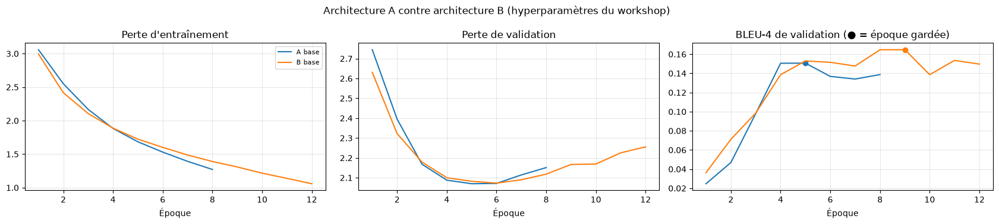

,paramètres,époques,meilleure époque,minutes,BLEU-1 val,BLEU-4 val,BLEU-4 entraînement,écart entr. - val
modèle,,,,,,,,
A base,6603658,8,5,1.9,0.571,0.151,0.242,0.092
B base,7259018,12,9,2.7,0.587,0.165,0.311,0.146


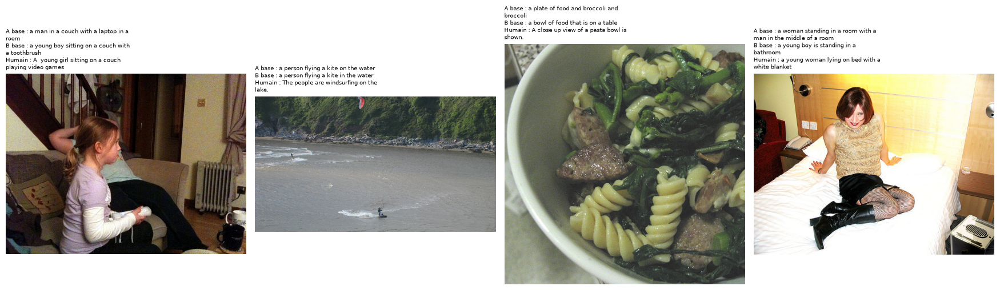

In [15]:
entrainer("A base", CONFIG_A, ids_train_comparaison)
entrainer("B base", CONFIG_B, ids_train_comparaison)

courbes(["A base", "B base"], "Architecture A contre architecture B (hyperparamètres du workshop)")
display(tableau(["A base", "B base"]))
exemples(["A base", "B base"], ids_val)

### Analyse : A contre B

| | A base | B base |
|---|---|---|
| BLEU-1 de validation | 0,571 | **0,587** |
| BLEU-4 de validation | 0,151 | **0,165** |
| écart entraînement - validation | **0,092** | 0,146 |
| meilleure époque / époques | 5 / 8 | 9 / 12 |
| paramètres entraînés | 6,6 M | 7,3 M |

- **À réglages égaux, B est meilleur :** +0,014 de BLEU-4 et +0,016 de BLEU-1. Il cite mieux les objets et construit de meilleures phrases. L'écart dépasse notre seuil de 0,005.
- **Mais B apprend davantage par cœur :** son écart entre entraînement et validation est de 0,146 contre 0,092. Avec seulement 1 000 photos, ses paramètres supplémentaires mémorisent les légendes d'entraînement. Le Dropout (section 9.4) devra corriger ce point.
- **L'arrêt anticipé est utile :** pour les deux modèles, la perte de validation remonte après 5 ou 6 époques alors que la perte d'entraînement continue de baisser. Les poids de la meilleure époque ont bien été gardés.
- **À confirmer :** sur 1 000 photos, cet avantage reste indicatif. La section 8 cherche d'où il vient, et la section 10 le vérifie avec beaucoup plus de photos.

## 8. Ce qu'apporte chaque modification de B

B change trois éléments à la fois. Pour savoir ce que **chacun** apporte, nous ajoutons à A **une seule** modification à la fois (étude d'ablation) :

| Modèle | CNN | RNN | Mémoire de départ |
|---|---|---|---|
| A base | InceptionV3 | GRU | zéros |
| A + InceptionResNetV2 | **InceptionResNetV2** | GRU | zéros |
| A + LSTM | InceptionV3 | **LSTM** | zéros |
| A + mémoire de départ | InceptionV3 | GRU | **résumé de la photo** |
| B base | **InceptionResNetV2** | **LSTM** | **résumé de la photo** |

Si une modification n'apporte rien seule mais améliore B, cela montre que les modifications se complètent.

--- Entraînement : A + InceptionResNetV2 ---
Époque  1 - perte : 3.056 - perte val : 2.726 - BLEU-4 val : 0.041 - 24 s
Époque  2 - perte : 2.453 - perte val : 2.279 - BLEU-4 val : 0.081 - 12 s
Époque  3 - perte : 2.059 - perte val : 2.147 - BLEU-4 val : 0.101 - 12 s
Époque  4 - perte : 1.826 - perte val : 2.090 - BLEU-4 val : 0.150 - 12 s
Époque  5 - perte : 1.647 - perte val : 2.068 - BLEU-4 val : 0.166 - 12 s
Époque  6 - perte : 1.507 - perte val : 2.061 - BLEU-4 val : 0.157 - 12 s
Époque  7 - perte : 1.382 - perte val : 2.095 - BLEU-4 val : 0.153 - 12 s
Époque  8 - perte : 1.276 - perte val : 2.124 - BLEU-4 val : 0.155 - 12 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 5 - BLEU-4 val : 0.166 - durée : 1.8 min

--- Entraînement : A + LSTM ---
Époque  1 - perte : 3.112 - perte val : 2.767 - BLEU-4 val : 0.022 - 25 s
Époque  2 - perte : 2.567 - perte val : 2.467 - BLEU-4 val : 0.034 - 13 s
Époque  3 - perte : 2.324 - perte val : 2.291 - BLEU-4 val : 0.060 - 

,paramètres,époques,meilleure époque,minutes,BLEU-1 val,BLEU-4 val,BLEU-4 entraînement,écart entr. - val
modèle,,,,,,,,
A base,6603658,8,5,1.9,0.571,0.151,0.242,0.092
A + InceptionResNetV2,6472586,8,5,1.8,0.580,0.166,0.233,0.067
A + LSTM,7126922,14,11,3.3,0.562,0.149,0.396,0.248
A + mémoire de départ,6735242,7,4,1.7,0.567,0.152,0.222,0.070
B base,7259018,12,9,2.7,0.587,0.165,0.311,0.146


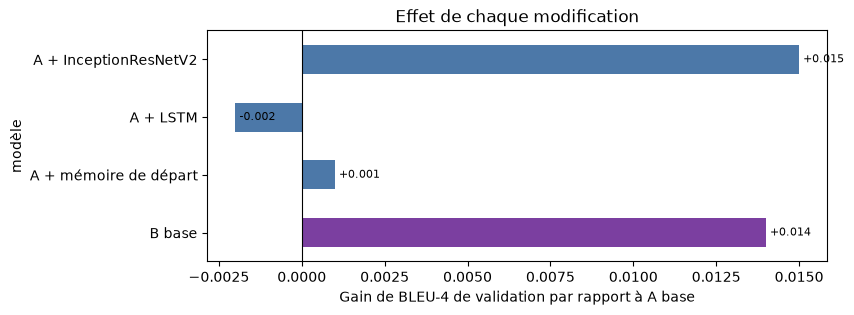

In [16]:
ablation = {
    "A + InceptionResNetV2": dict(CONFIG_A, cnn="InceptionResNetV2"),
    "A + LSTM": dict(CONFIG_A, rnn="lstm"),
    "A + mémoire de départ": dict(CONFIG_A, etat_initial=True),
}
for nom, config in ablation.items():
    entrainer(nom, config, ids_train_comparaison)

noms_ablation = ["A base"] + list(ablation) + ["B base"]
resultat_ablation = tableau(noms_ablation)
display(resultat_ablation)

# Gain de BLEU-4 de validation par rapport à A base
gains = resultat_ablation["BLEU-4 val"] - resultat_ablation.loc["A base", "BLEU-4 val"]
ax = gains.drop("A base").plot.barh(figsize=(8, 3), color=["#4C78A8"] * 3 + ["#7B3FA0"])
ax.axvline(0, color="black", lw=0.8)
for k, v in enumerate(gains.drop("A base")):
    ax.text(v, k, f" {v:+.3f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Gain de BLEU-4 de validation par rapport à A base")
ax.set_title("Effet de chaque modification")
plt.show()

### Analyse : effet de chaque modification

| Modification ajoutée à A | Gain de BLEU-4 | écart entr. - val | Conclusion |
|---|---|---|---|
| InceptionResNetV2 | **+0,015** | 0,067 | tout le gain, et moins d'apprentissage par cœur |
| LSTM | -0,002 | 0,248 | aucun gain, fort apprentissage par cœur |
| mémoire de départ | +0,001 | 0,070 | pas d'effet significatif sur le score |
| les trois (B) | +0,014 | 0,146 | |

- **Le meilleur CNN apporte tout le gain :** seul, il fait aussi bien que B (0,166 contre 0,165), avec moins de paramètres (6,5 M) et moins d'apprentissage par cœur. **L'hypothèse 1 est confirmée.**
- **Le LSTM seul n'apporte rien sur 1 000 photos :** il apprend fortement par cœur (écart 0,248, 14 époques). Ses paramètres supplémentaires mémorisent les légendes d'entraînement.
- **La mémoire de départ ne change pas le score (+0,001, sous le seuil), mais accélère l'apprentissage :** BLEU-4 de 0,055 dès la première époque contre 0,025 pour A, meilleure époque 4, et la perte de validation la plus basse du tableau (2,036). Le résumé de la photo aide le décodeur à démarrer. **L'hypothèse 2 n'est pas confirmée sur le score avec 1 000 photos.**
- **Les modifications ne s'additionnent pas avec peu de données :** B (0,165) fait jeu égal avec A + InceptionResNetV2 (0,166). Nous gardons B complet pour la suite : la section 10 vérifie si le LSTM et la mémoire de départ deviennent utiles avec plus de photos.

## 9. Réglage des hyperparamètres

### La méthode

Nous réglons les **mêmes hyperparamètres**, avec les **mêmes valeurs testées** et dans le **même ordre**, pour A et pour B. Chaque architecture a ainsi la même chance d'être bien réglée.

À chaque étape, **un seul hyperparamètre change**. Nous gardons la meilleure valeur (BLEU-4 de validation), puis nous passons à l'hyperparamètre suivant à partir de ce meilleur modèle. Nous savons ainsi d'où vient chaque amélioration.

**Règle d'équivalence :** sur 1 000 photos de validation, un écart de BLEU-4 inférieur à **0,005** n'est pas significatif (il peut venir du hasard de l'initialisation). Dans ce cas, nous **gardons la valeur actuelle**, c'est-à-dire celle du workshop ou celle déjà retenue.

### Les hyperparamètres réglés

| Étape | Hyperparamètre | Rôle | Valeur du workshop | Valeurs testées |
|---|---|---|---|---|
| 9.1 | taux d'apprentissage (`lr`) | taille des corrections des poids | 0,001 | 0,0003 et 0,003 |
| 9.2 | taille du RNN (`units`) | taille de la mémoire et de l'attention | 512 | 256 et 1 024 |
| 9.3 | taille de l'embedding (`embedding_dim`) | taille des vecteurs de mots et des zones | 256 | 128 et 512 |
| 9.4 | Dropout | part des neurones éteints au hasard à l'entraînement | 0 | 0,3 et 0,5 |
| 9.5 | taille des lots (`batch_size`) | nombre de légendes par correction | 64 | 32 et 128 |

**Pourquoi cet ordre ?** Le taux d'apprentissage agit sur tout l'entraînement : nous le réglons en premier. Viennent ensuite les tailles du modèle (`units`, `embedding_dim`), puis le Dropout, qui corrige le surapprentissage d'un modèle de taille donnée. La taille des lots, liée à la vitesse d'entraînement, est réglée en dernier.

In [17]:
MEILLEUR = {"A": "A base", "B": "B base"}     # meilleur modèle actuel de chaque architecture


def choisir(noms, actuel):
    # Meilleur BLEU-4 de validation ; si l'écart avec le modèle actuel est trop faible, on garde l'actuel
    meilleur = max(noms, key=lambda n: RESULTATS[n]["val"]["BLEU-4"])
    ecart = RESULTATS[meilleur]["val"]["BLEU-4"] - RESULTATS[actuel]["val"]["BLEU-4"]
    if meilleur != actuel and ecart < SEUIL_SIGNIFICATIF:
        return actuel
    return meilleur


def etape(param, valeurs, libelle):
    # Teste plusieurs valeurs d'un hyperparamètre, pour A puis pour B, à partir de leur meilleur modèle
    lignes = []
    for arch in ["A", "B"]:
        actuel = MEILLEUR[arch]
        config = RESULTATS[actuel]["config"]
        noms = {config[param]: actuel}                     # la valeur actuelle est déjà entraînée
        for v in valeurs:
            if v != config[param]:
                nom = f"{arch} {libelle} {str(v).replace('.', ',')}"
                entrainer(nom, dict(config, **{param: v}), ids_train_comparaison)
                noms[v] = nom
        MEILLEUR[arch] = choisir(list(noms.values()), actuel)
        for v, nom in sorted(noms.items()):
            lignes.append({"architecture": arch, libelle: v, "modèle": nom,
                           "BLEU-1 val": RESULTATS[nom]["val"]["BLEU-1"],
                           "BLEU-4 val": RESULTATS[nom]["val"]["BLEU-4"],
                           "écart entr. - val": RESULTATS[nom]["train"]["BLEU-4"] - RESULTATS[nom]["val"]["BLEU-4"],
                           "époques": RESULTATS[nom]["époques"], "retenu": nom == MEILLEUR[arch]})
        courbes(list(dict(sorted(noms.items())).values()), f"Architecture {arch} : {libelle}")

    resultat = pd.DataFrame(lignes)
    display(resultat.set_index(["architecture", libelle]).round(3))

    # Graphique : BLEU-4 de validation selon la valeur, pour A et B
    pivot = resultat.pivot(index=libelle, columns="architecture", values="BLEU-4 val")
    ax = pivot.plot.bar(figsize=(7, 3.6), rot=0, color={"A": "#4C78A8", "B": "#7B3FA0"})
    ax.set_ylim(pivot.min().min() - 0.02, pivot.max().max() + 0.01)
    ax.set_ylabel("BLEU-4 de validation")
    ax.set_title(f"Effet de : {libelle}")
    ax.grid(axis="y", alpha=0.3)
    plt.show()
    print("Retenu pour A :", MEILLEUR["A"], "- retenu pour B :", MEILLEUR["B"])
    return resultat

### 9.1 Taux d'apprentissage

Le taux d'apprentissage fixe la **taille des corrections** des poids à chaque lot :

- **trop petit** (0,0003) : l'apprentissage est lent, le modèle peut ne pas atteindre son meilleur niveau avant l'arrêt ;
- **trop grand** (0,003) : les corrections dépassent la bonne direction, la perte oscille ;
- **0,001** est la valeur par défaut d'Adam, utilisée au workshop.

**Question :** la valeur par défaut est-elle la bonne pour nos deux architectures ?

--- Entraînement : A taux d'apprentissage 0,0003 ---
Époque  1 - perte : 3.189 - perte val : 2.919 - BLEU-4 val : 0.000 - 23 s
Époque  2 - perte : 2.777 - perte val : 2.667 - BLEU-4 val : 0.006 - 13 s
Époque  3 - perte : 2.501 - perte val : 2.417 - BLEU-4 val : 0.067 - 13 s
Époque  4 - perte : 2.208 - perte val : 2.253 - BLEU-4 val : 0.094 - 13 s
Époque  5 - perte : 2.016 - perte val : 2.191 - BLEU-4 val : 0.114 - 13 s
Époque  6 - perte : 1.883 - perte val : 2.153 - BLEU-4 val : 0.128 - 13 s
Époque  7 - perte : 1.770 - perte val : 2.149 - BLEU-4 val : 0.147 - 13 s
Époque  8 - perte : 1.671 - perte val : 2.149 - BLEU-4 val : 0.135 - 13 s
Époque  9 - perte : 1.580 - perte val : 2.165 - BLEU-4 val : 0.135 - 13 s
Époque 10 - perte : 1.493 - perte val : 2.157 - BLEU-4 val : 0.137 - 13 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 7 - BLEU-4 val : 0.147 - durée : 2.3 min

--- Entraînement : A taux d'apprentissage 0,003 ---
Époque  1 - perte : 3.201 - perte val : 2

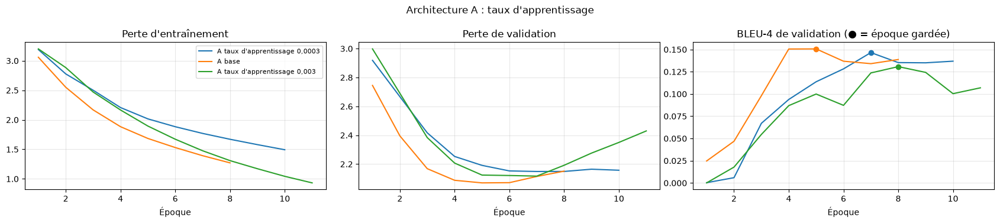

--- Entraînement : B taux d'apprentissage 0,0003 ---
Époque  1 - perte : 3.199 - perte val : 2.860 - BLEU-4 val : 0.000 - 27 s
Époque  2 - perte : 2.753 - perte val : 2.650 - BLEU-4 val : 0.020 - 13 s
Époque  3 - perte : 2.479 - perte val : 2.404 - BLEU-4 val : 0.068 - 12 s
Époque  4 - perte : 2.217 - perte val : 2.266 - BLEU-4 val : 0.095 - 13 s
Époque  5 - perte : 2.049 - perte val : 2.201 - BLEU-4 val : 0.110 - 12 s
Époque  6 - perte : 1.930 - perte val : 2.167 - BLEU-4 val : 0.112 - 12 s
Époque  7 - perte : 1.836 - perte val : 2.148 - BLEU-4 val : 0.132 - 12 s
Époque  8 - perte : 1.758 - perte val : 2.141 - BLEU-4 val : 0.133 - 13 s
Époque  9 - perte : 1.687 - perte val : 2.143 - BLEU-4 val : 0.142 - 13 s
Époque 10 - perte : 1.618 - perte val : 2.140 - BLEU-4 val : 0.136 - 13 s
Époque 11 - perte : 1.556 - perte val : 2.145 - BLEU-4 val : 0.154 - 13 s
Époque 12 - perte : 1.499 - perte val : 2.155 - BLEU-4 val : 0.148 - 13 s
Époque 13 - perte : 1.444 - perte val : 2.170 - BLEU-4 val 

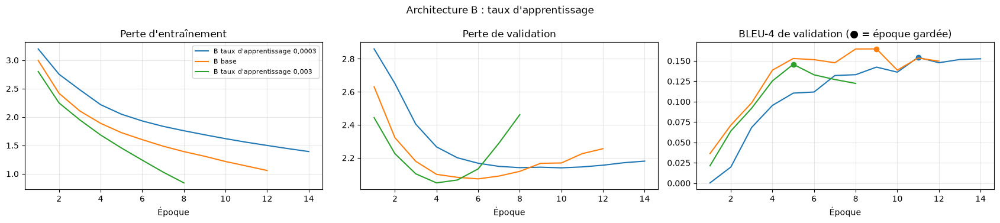

modèle  BLEU-1 val  \
architecture taux d'apprentissage                                              
A            0.0003                A taux d'apprentissage 0,0003       0.551   
             0.0010                                       A base       0.571   
             0.0030                 A taux d'apprentissage 0,003       0.532   
B            0.0003                B taux d'apprentissage 0,0003       0.581   
             0.0010                                       B base       0.587   
             0.0030                 B taux d'apprentissage 0,003       0.565   

                                   BLEU-4 val  écart entr. - val  époques  \
architecture taux d'apprentissage                                           
A            0.0003                     0.147              0.072       10   
             0.0010                     0.151              0.092        8   
             0.0030                     0.131              0.129       11   
B            0.0003                     0.154              0.118       14   
             0.0010                     0.165              0.146       12   
             0.0030                     0.146              0.088        8   

                                   retenu  
architecture taux d'apprentissage          
A            0.0003                 False  
             0.0010                  True  
             0.0030                 False  
B            0.0003                 False  
             0.0010                  True  
             0.0030                 False

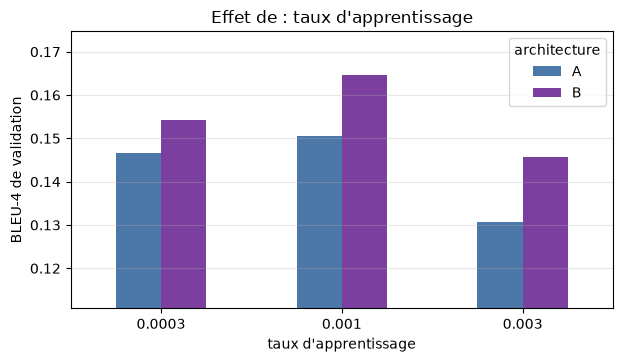

Retenu pour A : A base - retenu pour B : B base


In [18]:
resultat_lr = etape("lr", [0.0003, 0.001, 0.003], "taux d'apprentissage")

### Analyse : taux d'apprentissage

| Taux d'apprentissage | A : BLEU-4 | B : BLEU-4 |
|---|---|---|
| 0,0003 | 0,147 | 0,154 |
| **0,001** | **0,151** | **0,165** |
| 0,003 | 0,131 | 0,146 |

- **0,001 reste le meilleur pour les deux architectures :** c'est la valeur par défaut d'Adam, utilisée au workshop.
- **0,0003 est trop lent :** l'entraînement dure plus longtemps (10 époques pour A, 14 pour B) et n'atteint pas le meilleur niveau.
- **0,003 fait des corrections trop grandes :** B atteint une perte d'entraînement de 0,84 à l'époque 8, alors que sa perte de validation remonte dès l'époque 5. Le modèle apprend très vite par cœur, et le BLEU-1 baisse aussi (0,532 pour A).
- **Retenu : 0,001** pour A et B.

### 9.2 Taille du RNN (`units`)

`units` est la taille de la **mémoire** du RNN et de l'espace de calcul de l'attention :

- **plus grand** (1 024) : le modèle peut retenir plus d'informations, mais il a beaucoup plus de paramètres et risque d'apprendre par cœur ;
- **plus petit** (256) : le modèle est plus léger et plus rapide, mais il peut manquer de capacité.

**Question :** quelle taille donne le meilleur compromis entre qualité et nombre de paramètres ?

--- Entraînement : A units 256 ---
Époque  1 - perte : 3.165 - perte val : 2.917 - BLEU-4 val : 0.000 - 23 s
Époque  2 - perte : 2.741 - perte val : 2.574 - BLEU-4 val : 0.021 - 12 s
Époque  3 - perte : 2.437 - perte val : 2.415 - BLEU-4 val : 0.041 - 12 s
Époque  4 - perte : 2.224 - perte val : 2.241 - BLEU-4 val : 0.083 - 12 s
Époque  5 - perte : 1.983 - perte val : 2.137 - BLEU-4 val : 0.102 - 12 s
Époque  6 - perte : 1.795 - perte val : 2.082 - BLEU-4 val : 0.131 - 13 s
Époque  7 - perte : 1.642 - perte val : 2.083 - BLEU-4 val : 0.139 - 12 s
Époque  8 - perte : 1.519 - perte val : 2.097 - BLEU-4 val : 0.151 - 12 s
Époque  9 - perte : 1.406 - perte val : 2.131 - BLEU-4 val : 0.144 - 12 s
Époque 10 - perte : 1.305 - perte val : 2.143 - BLEU-4 val : 0.134 - 12 s
Époque 11 - perte : 1.208 - perte val : 2.190 - BLEU-4 val : 0.141 - 12 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 8 - BLEU-4 val : 0.151 - durée : 2.4 min

--- Entraînement : A units 1024 ---
É

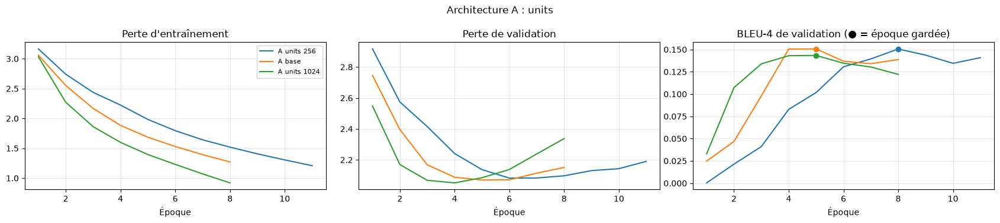

--- Entraînement : B units 256 ---
Époque  1 - perte : 3.149 - perte val : 2.827 - BLEU-4 val : 0.002 - 24 s
Époque  2 - perte : 2.655 - perte val : 2.512 - BLEU-4 val : 0.035 - 11 s
Époque  3 - perte : 2.389 - perte val : 2.390 - BLEU-4 val : 0.035 - 11 s
Époque  4 - perte : 2.226 - perte val : 2.269 - BLEU-4 val : 0.058 - 11 s
Époque  5 - perte : 2.045 - perte val : 2.179 - BLEU-4 val : 0.089 - 11 s
Époque  6 - perte : 1.897 - perte val : 2.128 - BLEU-4 val : 0.110 - 11 s
Époque  7 - perte : 1.764 - perte val : 2.094 - BLEU-4 val : 0.130 - 11 s
Époque  8 - perte : 1.651 - perte val : 2.089 - BLEU-4 val : 0.155 - 11 s
Époque  9 - perte : 1.549 - perte val : 2.094 - BLEU-4 val : 0.153 - 11 s
Époque 10 - perte : 1.455 - perte val : 2.105 - BLEU-4 val : 0.155 - 11 s
Époque 11 - perte : 1.374 - perte val : 2.142 - BLEU-4 val : 0.154 - 11 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 8 - BLEU-4 val : 0.155 - durée : 2.3 min

--- Entraînement : B units 1024 ---
É

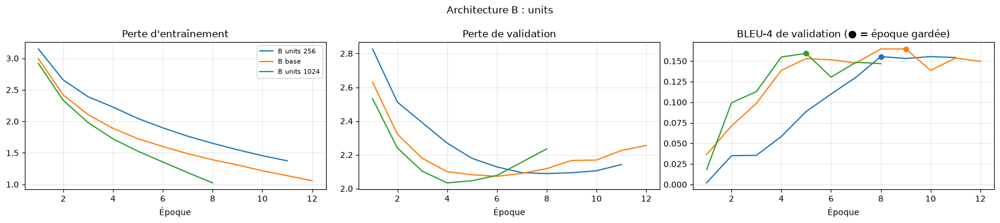

modèle  BLEU-1 val  BLEU-4 val  écart entr. - val  \
architecture units                                                            
A            256     A units 256       0.568       0.151              0.124   
             512          A base       0.571       0.151              0.092   
             1024   A units 1024       0.565       0.143              0.151   
B            256     B units 256       0.573       0.155              0.051   
             512          B base       0.587       0.165              0.146   
             1024   B units 1024       0.585       0.159              0.094   

                    époques  retenu  
architecture units                   
A            256         11   False  
             512          8    True  
             1024         8   False  
B            256         11   False  
             512         12    True  
             1024         8   False

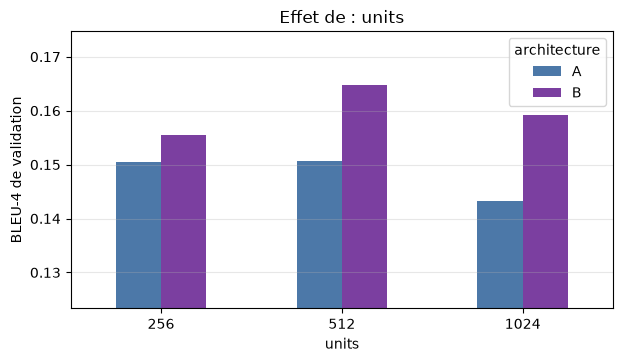

Retenu pour A : A base - retenu pour B : B base


In [19]:
resultat_units = etape("units", [256, 512, 1024], "units")

### Analyse : taille du RNN

| units | A : BLEU-4 | B : BLEU-4 | paramètres (A / B) |
|---|---|---|---|
| 256 | 0,151 | 0,155 | 3,9 M / 4,1 M |
| **512** | **0,151** | **0,165** | 6,6 M / 7,3 M |
| 1 024 | 0,143 | 0,159 | 14,0 M / 16,0 M |

- **Pour A**, 256 et 512 sont à égalité : selon notre règle d'équivalence, nous gardons la valeur actuelle, 512.
- **Pour B**, 512 est nettement meilleur. Avec 256, l'apprentissage par cœur est le plus faible (écart 0,051), mais le modèle manque de capacité.
- **1 024 double le nombre de paramètres sans rien apporter :** les deux modèles s'arrêtent dès l'époque 5 et apprennent plus vite par cœur. Avec 1 000 photos, une mémoire plus grande sert surtout à mémoriser.
- **Retenu : 512** pour A et B (valeur du workshop).

### 9.3 Taille de l'embedding (`embedding_dim`)

Le réseau ne comprend pas les mots : la couche **Embedding** remplace chaque mot par une liste de nombres, appelée **vecteur**. `embedding_dim` est la **longueur de cette liste**, c'est-à-dire le nombre de valeurs utilisées pour décrire chaque mot. Avec 256, le mot « dog » devient une liste de 256 nombres.

Ces nombres sont appris pendant l'entraînement. Comme vu au workshop *NLP RNN*, les mots de sens proche finissent avec des listes proches : « dog » et « puppy » se ressemblent, « dog » et « car » non.

Dans notre modèle, `embedding_dim` fixe aussi la taille de chacune des **64 zones de la photo** après l'encodeur : les mots et les zones ont la même taille, ce qui permet de les coller avant le RNN.

- **plus grand** (512) : plus de valeurs pour décrire chaque mot et chaque zone, donc des descriptions plus riches ;
- **plus petit** (128) : un modèle plus léger, avec moins de risque d'apprendre par cœur.

**Question :** des descriptions plus riches des mots et des zones améliorent-elles les légendes ?

--- Entraînement : A embedding 128 ---
Époque  1 - perte : 3.054 - perte val : 2.716 - BLEU-4 val : 0.025 - 24 s
Époque  2 - perte : 2.473 - perte val : 2.315 - BLEU-4 val : 0.080 - 13 s
Époque  3 - perte : 2.099 - perte val : 2.174 - BLEU-4 val : 0.099 - 13 s
Époque  4 - perte : 1.867 - perte val : 2.126 - BLEU-4 val : 0.132 - 12 s
Époque  5 - perte : 1.694 - perte val : 2.107 - BLEU-4 val : 0.135 - 13 s
Époque  6 - perte : 1.551 - perte val : 2.131 - BLEU-4 val : 0.139 - 12 s
Époque  7 - perte : 1.422 - perte val : 2.145 - BLEU-4 val : 0.140 - 13 s
Époque  8 - perte : 1.315 - perte val : 2.191 - BLEU-4 val : 0.145 - 13 s
Époque  9 - perte : 1.217 - perte val : 2.245 - BLEU-4 val : 0.126 - 13 s
Époque 10 - perte : 1.122 - perte val : 2.252 - BLEU-4 val : 0.134 - 12 s
Époque 11 - perte : 1.035 - perte val : 2.304 - BLEU-4 val : 0.136 - 13 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 8 - BLEU-4 val : 0.145 - durée : 2.5 min

--- Entraînement : A embedding 51

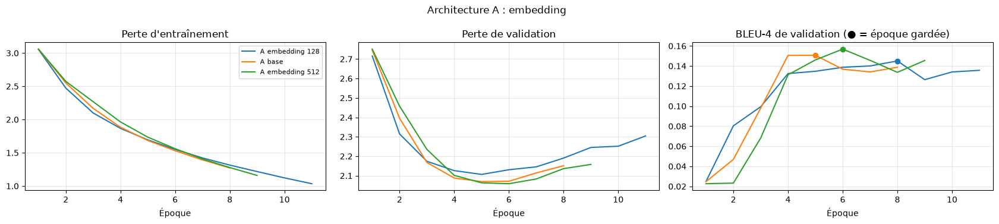

--- Entraînement : B embedding 128 ---
Époque  1 - perte : 3.022 - perte val : 2.685 - BLEU-4 val : 0.002 - 24 s
Époque  2 - perte : 2.474 - perte val : 2.370 - BLEU-4 val : 0.054 - 12 s
Époque  3 - perte : 2.161 - perte val : 2.201 - BLEU-4 val : 0.094 - 12 s
Époque  4 - perte : 1.936 - perte val : 2.121 - BLEU-4 val : 0.135 - 12 s
Époque  5 - perte : 1.771 - perte val : 2.097 - BLEU-4 val : 0.135 - 12 s
Époque  6 - perte : 1.645 - perte val : 2.083 - BLEU-4 val : 0.154 - 12 s
Époque  7 - perte : 1.530 - perte val : 2.097 - BLEU-4 val : 0.155 - 12 s
Époque  8 - perte : 1.434 - perte val : 2.118 - BLEU-4 val : 0.163 - 12 s
Époque  9 - perte : 1.342 - perte val : 2.156 - BLEU-4 val : 0.160 - 12 s
Époque 10 - perte : 1.251 - perte val : 2.174 - BLEU-4 val : 0.152 - 12 s
Époque 11 - perte : 1.171 - perte val : 2.230 - BLEU-4 val : 0.152 - 12 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 8 - BLEU-4 val : 0.163 - durée : 2.4 min

--- Entraînement : B embedding 51

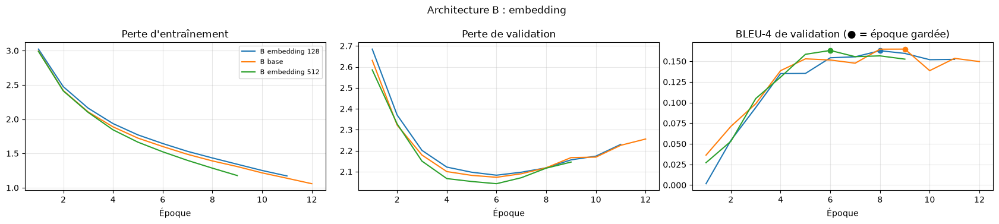

modèle  BLEU-1 val  BLEU-4 val  \
architecture embedding                                            
A            128        A embedding 128       0.545       0.145   
             256                 A base       0.571       0.151   
             512        A embedding 512       0.577       0.157   
B            128        B embedding 128       0.585       0.163   
             256                 B base       0.587       0.165   
             512        B embedding 512       0.572       0.163   

                        écart entr. - val  époques  retenu  
architecture embedding                                      
A            128                    0.221       11   False  
             256                    0.092        8   False  
             512                    0.115        9    True  
B            128                    0.126       11   False  
             256                    0.146       12    True  
             512                    0.087        9   False

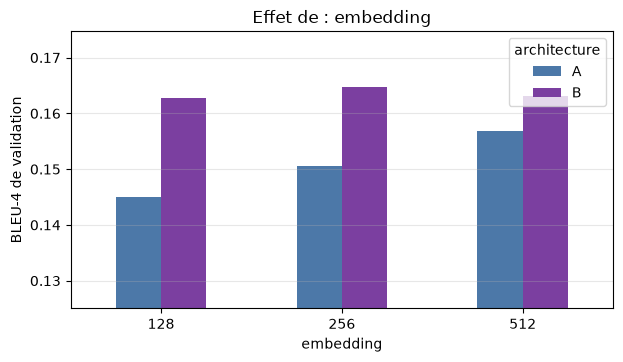

Retenu pour A : A embedding 512 - retenu pour B : B base


In [20]:
resultat_embedding = etape("embedding_dim", [128, 256, 512], "embedding")

### Analyse : taille de l'embedding

| embedding_dim | A : BLEU-4 | B : BLEU-4 |
|---|---|---|
| 128 | 0,145 | 0,163 |
| 256 | 0,151 | **0,165** |
| 512 | **0,157** | 0,163 |

- **Pour A**, 512 apporte +0,006, juste au-dessus du seuil : nous le retenons (9,3 M de paramètres). Avec 128, A apprend fortement par cœur (écart 0,221).
- **Pour B**, les trois valeurs sont équivalentes (écarts inférieurs à 0,005) : nous gardons la valeur actuelle, 256.
- **Une explication possible :** les zones d'InceptionV3 ont 2 048 valeurs, et A profite de les résumer en 512 valeurs plutôt qu'en 256. Pour B, le CNN donne déjà de meilleures caractéristiques et la taille de l'embedding compte peu.
- **Retenu : 512 pour A, 256 pour B.**

### 9.4 Dropout

Le Dropout (workshop *NLP RNN*) **éteint au hasard** une partie des neurones à chaque lot d'entraînement, ici entre les deux couches Dense du décodeur. Le modèle ne peut plus compter sur quelques neurones précis : il doit répartir l'information, ce qui limite l'apprentissage par cœur. Le Dropout est désactivé quand le modèle écrit une légende.

Nous avons vu que le modèle apprend vite par cœur (arrêt après quelques époques), surtout avec seulement 1 000 photos.

**Question :** le Dropout réduit-il l'écart entre l'entraînement et la validation, et améliore-t-il les légendes ?

--- Entraînement : A dropout 0,3 ---
Époque  1 - perte : 3.084 - perte val : 2.774 - BLEU-4 val : 0.032 - 28 s
Époque  2 - perte : 2.609 - perte val : 2.470 - BLEU-4 val : 0.025 - 15 s
Époque  3 - perte : 2.300 - perte val : 2.237 - BLEU-4 val : 0.076 - 15 s
Époque  4 - perte : 2.012 - perte val : 2.105 - BLEU-4 val : 0.132 - 15 s
Époque  5 - perte : 1.796 - perte val : 2.047 - BLEU-4 val : 0.140 - 16 s
Époque  6 - perte : 1.633 - perte val : 2.034 - BLEU-4 val : 0.155 - 15 s
Époque  7 - perte : 1.484 - perte val : 2.047 - BLEU-4 val : 0.150 - 15 s
Époque  8 - perte : 1.358 - perte val : 2.081 - BLEU-4 val : 0.147 - 15 s
Époque  9 - perte : 1.244 - perte val : 2.110 - BLEU-4 val : 0.151 - 15 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 6 - BLEU-4 val : 0.155 - durée : 2.5 min

--- Entraînement : A dropout 0,5 ---
Époque  1 - perte : 3.097 - perte val : 2.755 - BLEU-4 val : 0.023 - 27 s
Époque  2 - perte : 2.617 - perte val : 2.453 - BLEU-4 val : 0.036 - 15 

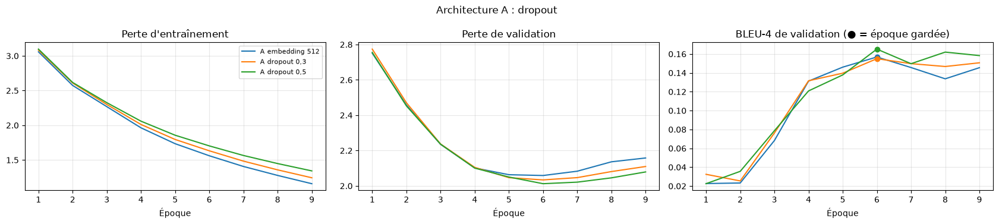

--- Entraînement : B dropout 0,3 ---
Époque  1 - perte : 3.008 - perte val : 2.627 - BLEU-4 val : 0.029 - 26 s
Époque  2 - perte : 2.461 - perte val : 2.337 - BLEU-4 val : 0.067 - 14 s
Époque  3 - perte : 2.162 - perte val : 2.180 - BLEU-4 val : 0.103 - 13 s
Époque  4 - perte : 1.938 - perte val : 2.077 - BLEU-4 val : 0.143 - 14 s
Époque  5 - perte : 1.766 - perte val : 2.054 - BLEU-4 val : 0.155 - 14 s
Époque  6 - perte : 1.640 - perte val : 2.034 - BLEU-4 val : 0.159 - 14 s
Époque  7 - perte : 1.526 - perte val : 2.045 - BLEU-4 val : 0.168 - 14 s
Époque  8 - perte : 1.428 - perte val : 2.071 - BLEU-4 val : 0.171 - 13 s
Époque  9 - perte : 1.335 - perte val : 2.113 - BLEU-4 val : 0.156 - 14 s
Époque 10 - perte : 1.243 - perte val : 2.102 - BLEU-4 val : 0.160 - 14 s
Époque 11 - perte : 1.155 - perte val : 2.160 - BLEU-4 val : 0.159 - 14 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 8 - BLEU-4 val : 0.171 - durée : 2.7 min

--- Entraînement : B dropout 0,5 --

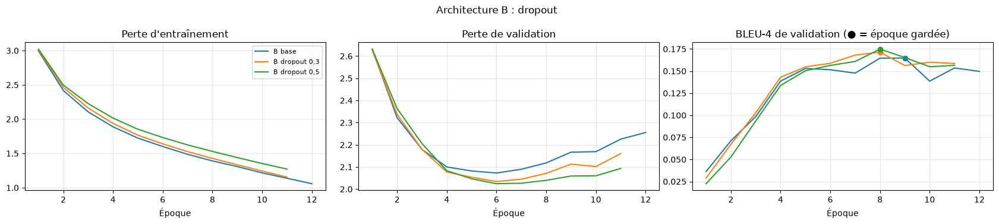

modèle  BLEU-1 val  BLEU-4 val  \
architecture dropout                                            
A            0.0      A embedding 512       0.577       0.157   
             0.3        A dropout 0,3       0.574       0.155   
             0.5        A dropout 0,5       0.579       0.165   
B            0.0               B base       0.587       0.165   
             0.3        B dropout 0,3       0.601       0.171   
             0.5        B dropout 0,5       0.606       0.175   

                      écart entr. - val  époques  retenu  
architecture dropout                                      
A            0.0                  0.115        9   False  
             0.3                  0.117        9   False  
             0.5                  0.087        9    True  
B            0.0                  0.146       12   False  
             0.3                  0.142       11   False  
             0.5                  0.120       11    True

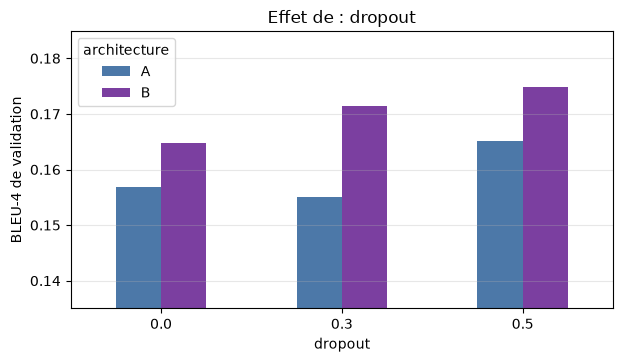

Retenu pour A : A dropout 0,5 - retenu pour B : B dropout 0,5


In [21]:
resultat_dropout = etape("dropout", [0.0, 0.3, 0.5], "dropout")

### Analyse : Dropout

| Dropout | A : BLEU-4 | A : écart entr. - val | B : BLEU-4 | B : écart entr. - val |
|---|---|---|---|---|
| 0 | 0,157 | 0,115 | 0,165 | 0,146 |
| 0,3 | 0,155 | 0,117 | 0,171 | 0,142 |
| **0,5** | **0,165** | **0,087** | **0,175** | **0,120** |

- **C'est le réglage le plus utile :** un Dropout de 0,5 améliore A de **+0,008** et B de **+0,010**.
- **Il réduit l'apprentissage par cœur,** comme prévu : l'écart entre entraînement et validation baisse pour les deux architectures.
- **B cite aussi mieux les objets :** son BLEU-1 passe de 0,587 à 0,606, le meilleur de tous les modèles à 1 000 photos.
- **Il faut un Dropout fort :** 0,3 n'apporte presque rien. Avec seulement 1 000 photos, notre principal problème était bien l'apprentissage par cœur.
- **Retenu : 0,5** pour A et B.

### 9.5 Taille des lots (`batch_size`)

La taille des lots fixe le nombre de légendes utilisées pour **chaque correction** des poids :

- **petits lots** (32) : deux fois plus de corrections par époque, mais chacune est plus « bruitée » ; ce bruit peut aider à mieux généraliser, au prix d'un entraînement plus long ;
- **grands lots** (128) : des corrections plus stables et un entraînement plus rapide, mais moins nombreuses.

**Question :** la taille des lots du workshop est-elle la bonne ?

--- Entraînement : A taille des lots 32 ---
Époque  1 - perte : 2.967 - perte val : 2.546 - BLEU-4 val : 0.045 - 52 s
Époque  2 - perte : 2.381 - perte val : 2.197 - BLEU-4 val : 0.092 - 21 s
Époque  3 - perte : 2.025 - perte val : 2.072 - BLEU-4 val : 0.129 - 21 s
Époque  4 - perte : 1.798 - perte val : 1.991 - BLEU-4 val : 0.164 - 21 s
Époque  5 - perte : 1.630 - perte val : 1.975 - BLEU-4 val : 0.158 - 21 s
Époque  6 - perte : 1.478 - perte val : 2.007 - BLEU-4 val : 0.150 - 21 s
Époque  7 - perte : 1.337 - perte val : 2.038 - BLEU-4 val : 0.151 - 21 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 4 - BLEU-4 val : 0.164 - durée : 3.0 min

--- Entraînement : A taille des lots 128 ---
Époque  1 - perte : 3.238 - perte val : 2.936 - BLEU-4 val : 0.000 - 25 s
Époque  2 - perte : 2.831 - perte val : 2.681 - BLEU-4 val : 0.025 - 12 s
Époque  3 - perte : 2.587 - perte val : 2.487 - BLEU-4 val : 0.046 - 12 s
Époque  4 - perte : 2.394 - perte val : 2.366 - BLEU-4 va

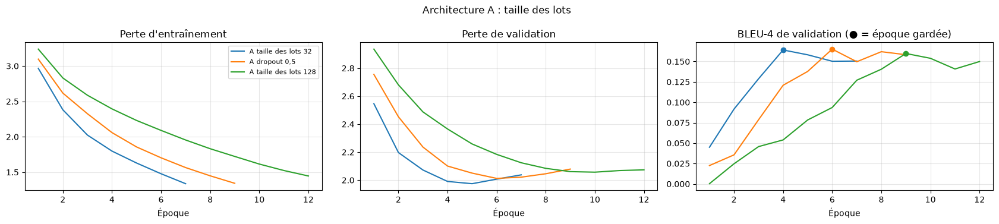

--- Entraînement : B taille des lots 32 ---
Époque  1 - perte : 2.845 - perte val : 2.475 - BLEU-4 val : 0.024 - 33 s
Époque  2 - perte : 2.332 - perte val : 2.206 - BLEU-4 val : 0.098 - 20 s
Époque  3 - perte : 2.038 - perte val : 2.074 - BLEU-4 val : 0.142 - 20 s
Époque  4 - perte : 1.836 - perte val : 2.007 - BLEU-4 val : 0.168 - 21 s
Époque  5 - perte : 1.687 - perte val : 1.997 - BLEU-4 val : 0.163 - 20 s
Époque  6 - perte : 1.556 - perte val : 2.002 - BLEU-4 val : 0.170 - 20 s
Époque  7 - perte : 1.430 - perte val : 2.033 - BLEU-4 val : 0.156 - 21 s
Époque  8 - perte : 1.311 - perte val : 2.062 - BLEU-4 val : 0.178 - 21 s
Époque  9 - perte : 1.191 - perte val : 2.115 - BLEU-4 val : 0.154 - 20 s
Époque 10 - perte : 1.072 - perte val : 2.168 - BLEU-4 val : 0.156 - 20 s
Époque 11 - perte : 0.957 - perte val : 2.248 - BLEU-4 val : 0.158 - 20 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 8 - BLEU-4 val : 0.178 - durée : 4.0 min

--- Entraînement : B taille 

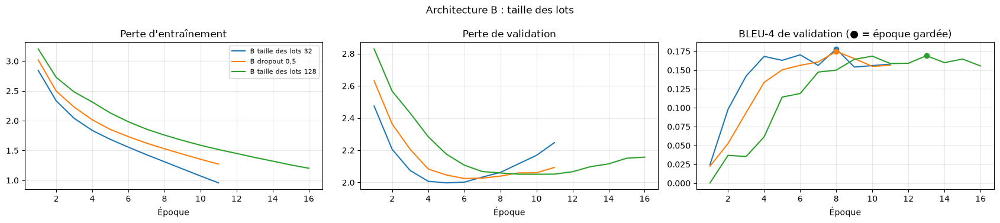

modèle  BLEU-1 val  BLEU-4 val  \
architecture taille des lots                                                  
A            32                A taille des lots 32       0.578       0.164   
             64                       A dropout 0,5       0.579       0.165   
             128              A taille des lots 128       0.584       0.160   
B            32                B taille des lots 32       0.606       0.178   
             64                       B dropout 0,5       0.606       0.175   
             128              B taille des lots 128       0.598       0.169   

                              écart entr. - val  époques  retenu  
architecture taille des lots                                      
A            32                           0.075        7   False  
             64                           0.087        9    True  
             128                          0.069       12   False  
B            32                           0.199       11   False  
             64                           0.120       11    True  
             128                          0.148       16   False

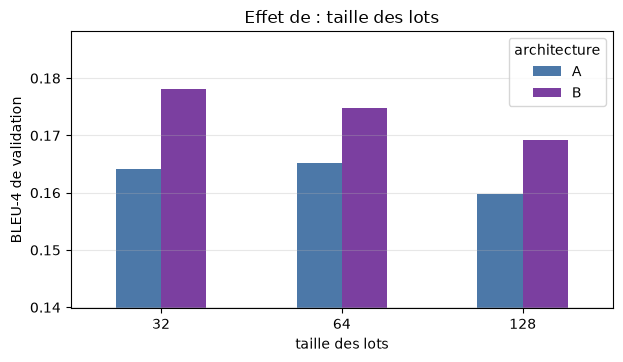

Retenu pour A : A dropout 0,5 - retenu pour B : B dropout 0,5


In [22]:
resultat_batch = etape("batch_size", [32, 64, 128], "taille des lots")

### Analyse : taille des lots

| Taille des lots | A : BLEU-4 | B : BLEU-4 | B : écart entr. - val |
|---|---|---|---|
| 32 | 0,164 | 0,178 | 0,199 |
| **64** | **0,165** | **0,175** | **0,120** |
| 128 | 0,160 | 0,169 | 0,148 |

- **Pour A**, 64 reste le meilleur.
- **Pour B**, les lots de 32 donnent +0,003, sous notre seuil de 0,005. Ils apprennent aussi beaucoup plus par cœur (écart 0,199 contre 0,120) et l'entraînement est 1,4 fois plus long (4,0 min contre 2,8). Selon notre règle, nous gardons 64.
- **Les lots de 128** font deux fois moins de corrections par époque : l'apprentissage est plus lent (jusqu'à 16 époques) et les scores plus bas.
- **Retenu : 64** pour A et B (valeur du workshop).

### 9.6 Bilan du réglage des hyperparamètres

,A workshop,A réglée,B de départ,B réglée
cnn,InceptionV3,InceptionV3,InceptionResNetV2,InceptionResNetV2
rnn,gru,gru,lstm,lstm
etat_initial,False,False,True,True
units,512,512,512,512
embedding_dim,256,512,256,256
dropout,0.0,0.5,0.0,0.5
lr,0.001,0.001,0.001,0.001
batch_size,64,64,64,64


,paramètres,époques,meilleure époque,minutes,BLEU-1 val,BLEU-4 val,BLEU-4 entraînement,écart entr. - val
modèle,,,,,,,,
B taille des lots 32,7259018,11,8,4.0,0.606,0.178,0.377,0.199
"B dropout 0,5",7259018,11,8,2.8,0.606,0.175,0.295,0.120
"B dropout 0,3",7259018,11,8,2.7,0.601,0.171,0.314,0.142
B taille des lots 128,7259018,16,13,3.1,0.598,0.169,0.317,0.148
A + InceptionResNetV2,6472586,8,5,1.8,0.580,0.166,0.233,0.067
B base,7259018,12,9,2.7,0.587,0.165,0.311,0.146
"A dropout 0,5",9325962,9,6,2.5,0.579,0.165,0.252,0.087
A taille des lots 32,9325962,7,4,3.0,0.578,0.164,0.239,0.075
B embedding 128,5701258,11,8,2.4,0.585,0.163,0.288,0.126


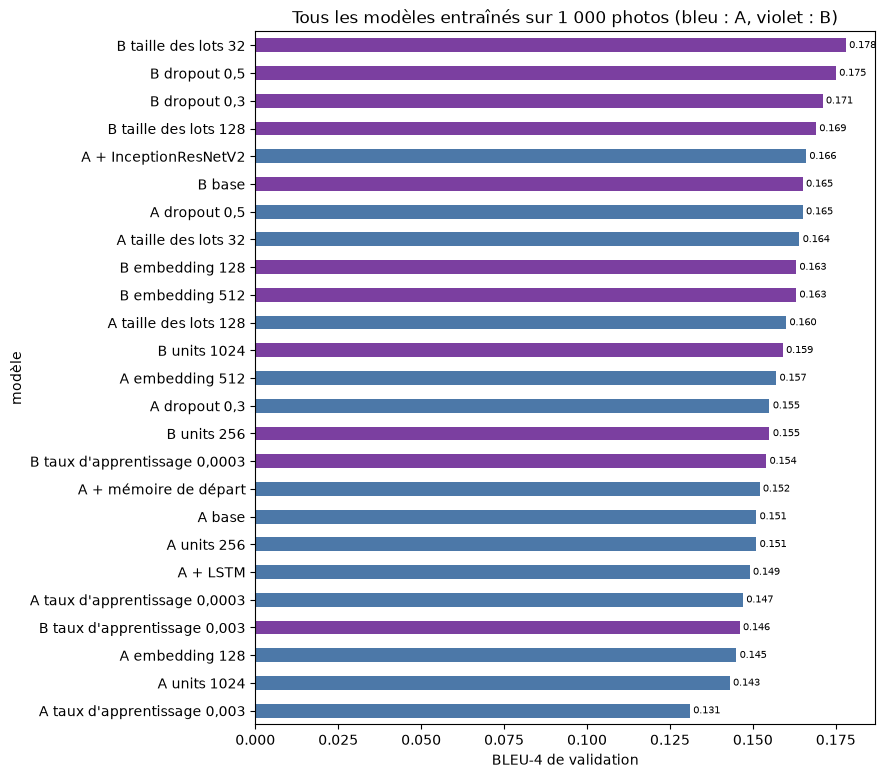

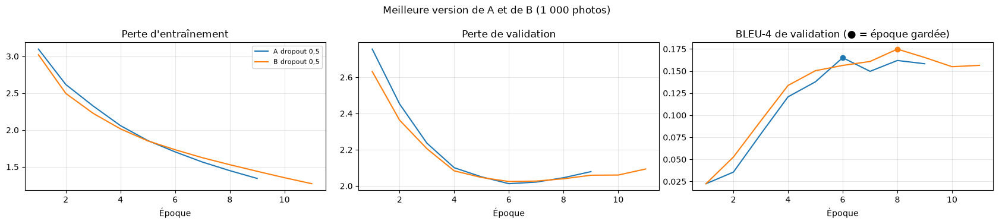

In [23]:
# Configuration de départ et configuration retenue pour chaque architecture
bilan_config = pd.DataFrame({
    "A workshop": CONFIG_A, "A réglée": RESULTATS[MEILLEUR["A"]]["config"],
    "B de départ": CONFIG_B, "B réglée": RESULTATS[MEILLEUR["B"]]["config"],
})
display(bilan_config)

# Tous les modèles entraînés sur 1 000 photos, du meilleur au moins bon
bilan = tableau(list(RESULTATS)).sort_values("BLEU-4 val", ascending=False)
display(bilan)

couleurs = ["#7B3FA0" if n.startswith("B") else "#4C78A8" for n in bilan.index]
ax = bilan["BLEU-4 val"].plot.barh(figsize=(8, 0.32 * len(bilan) + 1), color=couleurs)
for k, v in enumerate(bilan["BLEU-4 val"]):
    ax.text(v + 0.001, k, f"{v:.3f}", va="center", fontsize=7.5)
ax.invert_yaxis()
ax.set_xlabel("BLEU-4 de validation")
ax.set_title("Tous les modèles entraînés sur 1 000 photos (bleu : A, violet : B)")
plt.show()

courbes([MEILLEUR["A"], MEILLEUR["B"]], "Meilleure version de A et de B (1 000 photos)")

### Analyse : bilan des réglages

| | A | B |
|---|---|---|
| BLEU-4 avec les réglages du workshop | 0,151 | 0,165 |
| BLEU-4 après réglage | **0,165** | **0,175** |
| gain | +0,014 | +0,010 |
| réglages changés | embedding 512, Dropout 0,5 | Dropout 0,5 |

- **Les valeurs du workshop étaient déjà bien choisies :** taux d'apprentissage, `units` et taille des lots restent inchangés pour les deux architectures.
- **Le réglage décisif est le Dropout,** qui corrige l'apprentissage par cœur dû au faible nombre de photos.
- **B est au-dessus de A pour chacune des 15 valeurs testées :** son avantage ne dépend pas des réglages. Les 6 meilleurs modèles du classement utilisent tous InceptionResNetV2.
- **Limite :** nous avons réglé un hyperparamètre à la fois. Tester toutes les combinaisons demanderait 3⁵ = 243 entraînements par architecture (environ 20 heures) ; une interaction entre deux réglages a donc pu nous échapper.

## 10. Choix du modèle final : 20 000 puis 40 000 photos

Avec 1 000 photos, les écarts entre modèles sont petits et en partie dus au hasard. Pour choisir le modèle final de façon fiable, nous entraînons **la meilleure version de A et la meilleure version de B sur 20 000 photos** (environ 100 000 légendes), soit 20 fois plus d'exemples.

Lors de notre premier essai, passer de 5 000 à 20 000 photos avait été la plus forte amélioration (+0,03 de BLEU-4). Nous vérifions aussi si l'écart entre A et B se confirme avec plus de données.

**Le modèle final est celui qui obtient le meilleur BLEU-4 de validation.** Si l'écart entre A et B est inférieur à 0,005, nous gardons le plus simple, A.

--- Entraînement : A final (20 000 photos) ---
Époque  1 - perte : 1.918 - perte val : 1.576 - BLEU-4 val : 0.205 - 186 s
Époque  2 - perte : 1.532 - perte val : 1.480 - BLEU-4 val : 0.237 - 171 s
Époque  3 - perte : 1.422 - perte val : 1.456 - BLEU-4 val : 0.254 - 170 s
Époque  4 - perte : 1.346 - perte val : 1.452 - BLEU-4 val : 0.236 - 172 s
Époque  5 - perte : 1.284 - perte val : 1.458 - BLEU-4 val : 0.229 - 171 s
Époque  6 - perte : 1.229 - perte val : 1.466 - BLEU-4 val : 0.223 - 173 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 3 - BLEU-4 val : 0.254 - durée : 17.4 min

--- Entraînement : B final (20 000 photos) ---
Époque  1 - perte : 1.926 - perte val : 1.599 - BLEU-4 val : 0.216 - 184 s
Époque  2 - perte : 1.545 - perte val : 1.483 - BLEU-4 val : 0.236 - 168 s
Époque  3 - perte : 1.434 - perte val : 1.450 - BLEU-4 val : 0.253 - 171 s
Époque  4 - perte : 1.359 - perte val : 1.437 - BLEU-4 val : 0.250 - 166 s
Époque  5 - perte : 1.298 - perte val : 1

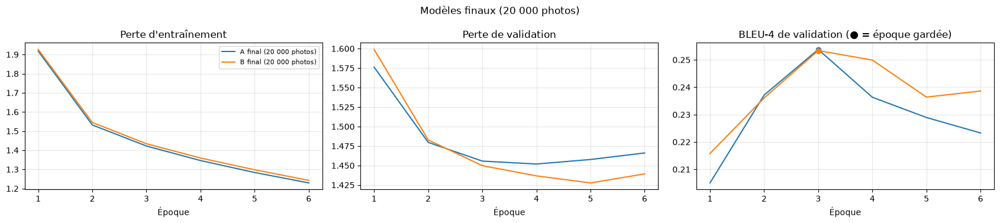

,paramètres,époques,meilleure époque,minutes,BLEU-1 val,BLEU-4 val,BLEU-4 entraînement,écart entr. - val
modèle,,,,,,,,
"A dropout 0,5",9325962,9,6,2.5,0.579,0.165,0.252,0.087
A final (20 000 photos),9325962,6,3,17.4,0.679,0.254,0.292,0.038
"B dropout 0,5",7259018,11,8,2.8,0.606,0.175,0.295,0.120
B final (20 000 photos),7259018,6,3,17.2,0.683,0.253,0.290,0.037


Modèle final : A final (20 000 photos)
Configuration : {'cnn': 'InceptionV3', 'rnn': 'gru', 'etat_initial': False, 'units': 512, 'embedding_dim': 512, 'dropout': 0.5, 'lr': 0.001, 'batch_size': 64}


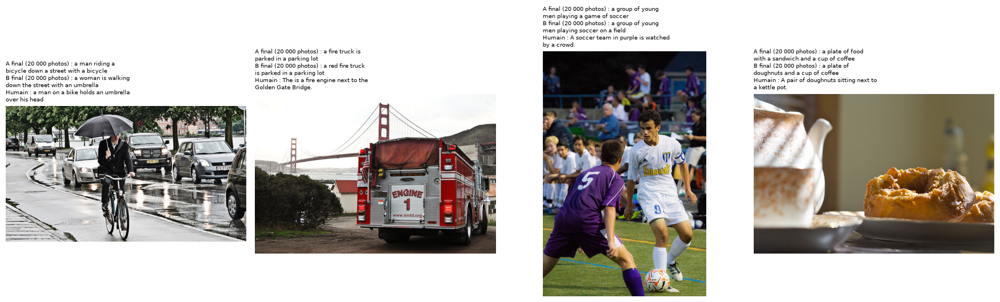

In [24]:
entrainer("A final (20 000 photos)", RESULTATS[MEILLEUR["A"]]["config"], ids_train)
entrainer("B final (20 000 photos)", RESULTATS[MEILLEUR["B"]]["config"], ids_train)

noms_finaux = [MEILLEUR["A"], "A final (20 000 photos)", MEILLEUR["B"], "B final (20 000 photos)"]
courbes(["A final (20 000 photos)", "B final (20 000 photos)"], "Modèles finaux (20 000 photos)")
display(tableau(noms_finaux))

NOM_FINAL = max(["A final (20 000 photos)", "B final (20 000 photos)"],
                key=lambda n: RESULTATS[n]["val"]["BLEU-4"])
FINAL = RESULTATS[NOM_FINAL]
CNN_FINAL = FINAL["config"]["cnn"]
print("Modèle final :", NOM_FINAL)
print("Configuration :", FINAL["config"])

exemples(["A final (20 000 photos)", "B final (20 000 photos)"], ids_val[4:])

### 10.1 Encore plus de données : 40 000 photos

Avec 20 000 photos, A et B sont **à égalité** (0,254 contre 0,253) : selon notre règle, nous aurions gardé A, le plus simple. Mais les deux modèles ont fortement progressé entre 1 000 et 20 000 photos. Nous vérifions donc si **deux fois plus de photos** permettent de départager les deux architectures.

- Nous entraînons les **mêmes configurations** qu'en section 10 sur **40 000 photos**, qui incluent les 20 000 précédentes. La validation et le test ne changent pas.
- Les caractéristiques des 20 000 nouvelles photos sont d'abord calculées avec les deux CNN.
- Le noyau a été redémarré avant cette étape pour libérer la mémoire du GPU (les 27 modèles entraînés y étaient gardés). Les configurations retenues sont donc réécrites dans la cellule, et le modèle A à 20 000 photos est rechargé depuis sa sauvegarde puis réévalué : il redonne bien 0,254.

**Le modèle final est le meilleur des trois candidats en BLEU-4 de validation :** A à 20 000 photos, A à 40 000 photos et B à 40 000 photos.

Photos d'entraînement : 40000
InceptionV3 : caractéristiques déjà calculées


I0000 00:00:1792585320.408836   90321 cuda_dnn.cc:442] Loaded cuDNN version 92600
Could not load symbol cuStreamGetGreenCtx. Error: /usr/lib/wsl/lib/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx
W0000 00:00:1792585322.247295   90321 bfc_allocator.cc:470] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.
E0000 00:00:1792585322.259970   90321 cuda_executor.cc:1365] [0] Failed to allocate device memory of 4.00GiB (4294967296 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:

InceptionResNetV2 : 20000 photos en 1102 s


E0000 00:00:1792586424.389547   90321 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


A final (20 000 photos) - BLEU-4 val : 0.254
--- Entraînement : A final (40 000 photos) ---
Époque  1 - perte : 1.754 - perte val : 1.478 - BLEU-4 val : 0.211 - 354 s
Époque  2 - perte : 1.454 - perte val : 1.409 - BLEU-4 val : 0.231 - 352 s
Époque  3 - perte : 1.374 - perte val : 1.388 - BLEU-4 val : 0.244 - 345 s
Époque  4 - perte : 1.320 - perte val : 1.385 - BLEU-4 val : 0.233 - 340 s
Époque  5 - perte : 1.276 - perte val : 1.387 - BLEU-4 val : 0.244 - 340 s
Époque  6 - perte : 1.237 - perte val : 1.396 - BLEU-4 val : 0.248 - 347 s
Époque  7 - perte : 1.203 - perte val : 1.407 - BLEU-4 val : 0.238 - 346 s
Époque  8 - perte : 1.171 - perte val : 1.426 - BLEU-4 val : 0.235 - 344 s
Époque  9 - perte : 1.142 - perte val : 1.436 - BLEU-4 val : 0.236 - 343 s
Arrêt anticipé : pas de progrès depuis 3 époques.
=> meilleure époque : 6 - BLEU-4 val : 0.248 - durée : 51.9 min

--- Entraînement : B final (40 000 photos) ---
Époque  1 - perte : 1.750 - perte val : 1.477 - BLEU-4 val : 0.237 - 34

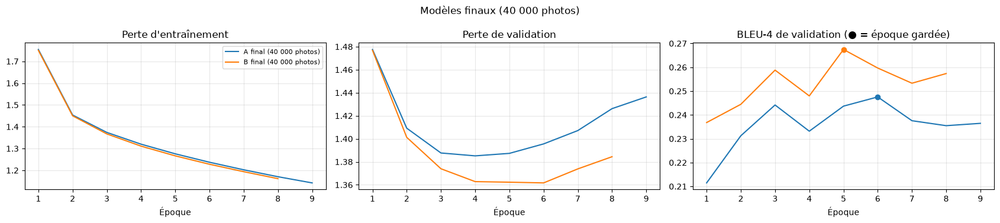

,paramètres,époques,meilleure époque,minutes,BLEU-1 val,BLEU-4 val,BLEU-4 entraînement,écart entr. - val
modèle,,,,,,,,
A final (40 000 photos),9325962,9,6,51.9,0.683,0.248,0.327,0.080
B final (40 000 photos),7259018,8,5,44.1,0.700,0.267,0.315,0.048


,20 000 photos,40 000 photos
A,0.254,0.248
B,0.253,0.267


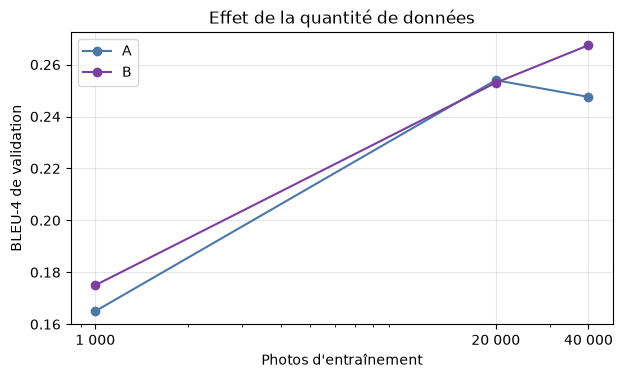

Modèle final : B final (40 000 photos)
Configuration : {'cnn': 'InceptionResNetV2', 'rnn': 'lstm', 'etat_initial': True, 'units': 512, 'embedding_dim': 256, 'dropout': 0.5, 'lr': 0.001, 'batch_size': 64}


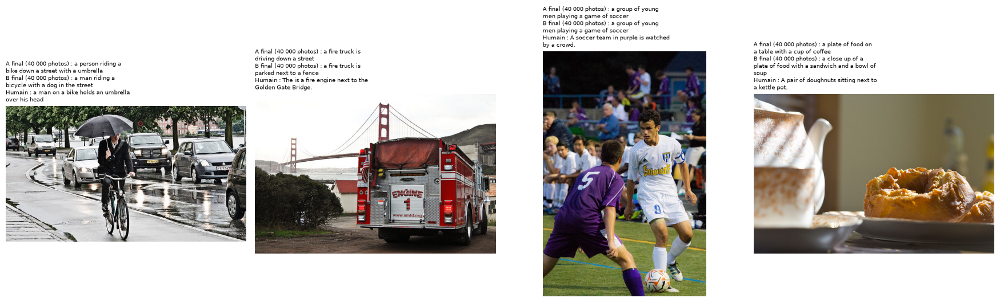

In [11]:
import gc

# Le noyau a été redémarré avant cette cellule pour libérer la mémoire du GPU :
# les configurations retenues en section 9 (tableau du bilan des réglages) sont réécrites ici
CONFIG_A_REGLEE = {"cnn": "InceptionV3", "rnn": "gru", "etat_initial": False, "units": 512,
                   "embedding_dim": 512, "dropout": 0.5, "lr": 0.001, "batch_size": 64}
CONFIG_B_REGLEE = {"cnn": "InceptionResNetV2", "rnn": "lstm", "etat_initial": True, "units": 512,
                   "embedding_dim": 256, "dropout": 0.5, "lr": 0.001, "batch_size": 64}

N_TRAIN_40K = 40000
ids_train_40k = ids[N_TEST + N_VAL:N_TEST + N_VAL + N_TRAIN_40K]   # inclut les 20 000 photos précédentes
print("Photos d'entraînement :", len(ids_train_40k))

# 1. Caractéristiques des 20 000 nouvelles photos
# Lots plus petits : InceptionResNetV2 demande beaucoup de mémoire sur le GPU
LOT_EXTRACTION = 8
for nom_cnn in cm.CNNS:
    extraire(ids_train_40k, nom_cnn)

# Les CNN ne servent plus pendant l'entraînement : on libère leur mémoire
del extracteurs
gc.collect()

# 2. Modèle A à 20 000 photos : rechargé depuis sa sauvegarde (section 13 de l'exécution précédente)
#    puis réévalué, pour vérifier qu'il redonne le même score qu'en section 10
enc20, dec20 = cm.construire(CONFIG_A_REGLEE, VOCAB_SIZE)
enc20.load_weights(SORTIE_DIR / "encodeur.weights.h5")
dec20.load_weights(SORTIE_DIR / "decodeur.weights.h5")
modele20 = {"encoder": enc20, "decoder": dec20}
RESULTATS["A final (20 000 photos)"] = {
    **modele20, "config": CONFIG_A_REGLEE, "val": evaluer(modele20, ids_val, VAL["InceptionV3"]),
}
print("A final (20 000 photos) - BLEU-4 val :", round(RESULTATS["A final (20 000 photos)"]["val"]["BLEU-4"], 3))

# 3. Mêmes configurations qu'en section 10, deux fois plus de photos
entrainer("A final (40 000 photos)", CONFIG_A_REGLEE, ids_train_40k)
entrainer("B final (40 000 photos)", CONFIG_B_REGLEE, ids_train_40k)

courbes(["A final (40 000 photos)", "B final (40 000 photos)"], "Modèles finaux (40 000 photos)")
display(tableau(["A final (40 000 photos)", "B final (40 000 photos)"]))

# 4. Comparaison avec les modèles à 20 000 photos (scores de la section 10)
comparaison_donnees = pd.DataFrame({
    "20 000 photos": {"A": 0.254, "B": 0.253},
    "40 000 photos": {"A": RESULTATS["A final (40 000 photos)"]["val"]["BLEU-4"],
                      "B": RESULTATS["B final (40 000 photos)"]["val"]["BLEU-4"]},
})
display(comparaison_donnees.round(3))

evolution = pd.DataFrame({"A": {1000: 0.165, 20000: 0.254}, "B": {1000: 0.175, 20000: 0.253}})
evolution.loc[40000] = comparaison_donnees["40 000 photos"]
ax = evolution.plot(marker="o", figsize=(7, 3.8), color={"A": "#4C78A8", "B": "#7B3FA0"})
ax.set_xscale("log")
ax.set_xticks([1000, 20000, 40000])
ax.set_xticklabels(["1 000", "20 000", "40 000"])
ax.set_xlabel("Photos d'entraînement")
ax.set_ylabel("BLEU-4 de validation")
ax.set_title("Effet de la quantité de données")
ax.grid(alpha=0.3)
plt.show()

# 5. Modèle final : le meilleur BLEU-4 de validation parmi les trois candidats
candidats = ["A final (20 000 photos)", "A final (40 000 photos)", "B final (40 000 photos)"]
NOM_FINAL = max(candidats, key=lambda n: RESULTATS[n]["val"]["BLEU-4"])
FINAL = RESULTATS[NOM_FINAL]
CNN_FINAL = FINAL["config"]["cnn"]
print("Modèle final :", NOM_FINAL)
print("Configuration :", FINAL["config"])

exemples(["A final (40 000 photos)", "B final (40 000 photos)"], ids_val[4:])

### Analyse : choix du modèle final

| BLEU-4 de validation | 1 000 photos | 20 000 photos | 40 000 photos |
|---|---|---|---|
| A (workshop) | 0,165 | **0,254** | 0,248 |
| B (notre proposition) | 0,175 | 0,253 | **0,267** |

| 40 000 photos | BLEU-1 val | écart entr. - val | meilleure époque | durée |
|---|---|---|---|---|
| A final | 0,683 | 0,080 | 6 / 9 | 51,9 min |
| B final | **0,700** | **0,048** | 5 / 8 | 44,1 min |

- **La quantité de données est le levier le plus fort :** de 1 000 à 20 000 photos, le BLEU-4 gagne +0,089 pour A et +0,078 pour B, bien plus que tous les réglages réunis, et l'apprentissage par cœur disparaît presque (écart de 0,038 et 0,037). **L'hypothèse 3 est confirmée.**
- **À 20 000 photos, A et B sont à égalité** (écart de 0,001).
- **À 40 000 photos, B continue de progresser** (0,267, BLEU-1 de 0,700) **alors que A plafonne** (0,248). La perte de validation de A remonte dès l'époque 4, et il apprend davantage par cœur (écart 0,080 contre 0,048).
- **Interprétation :** avec peu de données, seul le meilleur CNN aidait, et le LSTM apprenait par cœur. Avec 40 000 photos, B exploite les données supplémentaires grâce à son CNN plus précis, à son LSTM et à sa mémoire de départ, alors que A a atteint sa limite. Notre architecture était meilleure, mais il fallait assez de données pour le montrer.
- **Choix : B final (40 000 photos).** Il dépasse le meilleur A (0,254) de 0,013, au-delà de notre seuil de 0,005. Il a aussi moins de paramètres entraînés que A réglé (7,3 M contre 9,3 M) et s'entraîne plus vite (44 min contre 52).

### 10.2 Écrire la légende : tirage au hasard ou mot le plus probable ?

Pour écrire une légende, le modèle donne à chaque étape une probabilité à chacun des 5 001 mots. Il reste à **choisir** le mot :

- **tirage au hasard** selon ces probabilités : c'est la méthode du workshop (`tf.random.categorical`). Un mot peu probable peut être tiré, et la suite de la phrase dérive ;
- **mot le plus probable** (`argmax`) : la même photo donne toujours la même légende.

Nous comparons les deux sur le modèle final, sans le réentraîner. La méthode retenue est celle utilisée à la soutenance.

In [12]:
generation = pd.DataFrame({
    "tirage au hasard": evaluer(FINAL, ids_val, VAL[CNN_FINAL], mode="hasard"),
    "mot le plus probable": evaluer(FINAL, ids_val, VAL[CNN_FINAL], mode="glouton"),
}).T
display(generation.round(3))

# Une même photo légendée 3 fois au hasard, puis avec le mot le plus probable
f = VAL[CNN_FINAL][1:2]
print("Humain        :", legendes_brutes[ids_val[1]][0])
for k in range(3):
    ids_mots, _ = cm.generer(FINAL["encoder"], FINAL["decoder"], f, START_ID, MAX_LEN, "hasard", graine=100 + k)
    print(f"Hasard {k + 1}      :", " ".join(cm.ids_vers_mots(ids_mots[0], tokenizer.index_word, END_ID)))
print("Plus probable :", " ".join(legender(FINAL, f)[0][0]))

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
tirage au hasard,0.501,0.303,0.182,0.109
mot le plus probable,0.700,0.521,0.374,0.267


Humain        : The people are windsurfing on the lake.  
Hasard 1      : a person kite riding a river <unk> with a big parachute
Hasard 2      : two people are kiteboarding out in the ocean
Hasard 3      : a person flying a kite over the ocean
Plus probable : a person is surfing in the water with a kite


### Analyse : façon d'écrire la légende

| | BLEU-1 | BLEU-4 |
|---|---|---|
| tirage au hasard (workshop) | 0,501 | 0,109 |
| **mot le plus probable** | **0,700** | **0,267** |

- **Le mot le plus probable est bien meilleur** sur les quatre scores : le BLEU-4 est multiplié par **2,4**, sans réentraîner le modèle.
- **L'exemple le montre :** les trois tirages au hasard donnent trois phrases différentes, dont certaines dérivent (« a person kite riding a river `<unk>` with a big parachute »). Le mot le plus probable donne « a person is surfing in the water with a kite », proche de la légende humaine (« The people are windsurfing on the lake »).
- **Retenu : le mot le plus probable.** Il est aussi **déterministe** : une même photo donne toujours la même légende, ce qui rend la démonstration reproductible.
- **Limite :** cette méthode choisit chaque mot sans revenir en arrière, et peut répéter un mot. Le *beam search*, qui garde plusieurs phrases candidates, est une piste d'amélioration.

## 11. Évaluation finale sur le test

Le modèle final est figé : il a été choisi **uniquement** à partir de la validation. Nous le mesurons maintenant **une seule fois** sur les 1 000 photos de test, qu'aucun modèle n'a jamais vues. Ce score est donc une estimation honnête de la qualité du modèle sur des photos nouvelles.

**Transparence :** lors de l'exécution précédente, le modèle A à 20 000 photos avait été mesuré sur ce même test (BLEU-4 de 0,241). Ce résultat n'a servi à aucun choix : le passage à 40 000 photos et le choix de B reposent uniquement sur la validation.

,validation,test,"article Show, Attend and Tell"
BLEU-1,0.700,0.705,0.70
BLEU-2,0.521,0.525,0.49
BLEU-3,0.374,0.375,0.34
BLEU-4,0.267,0.267,0.24


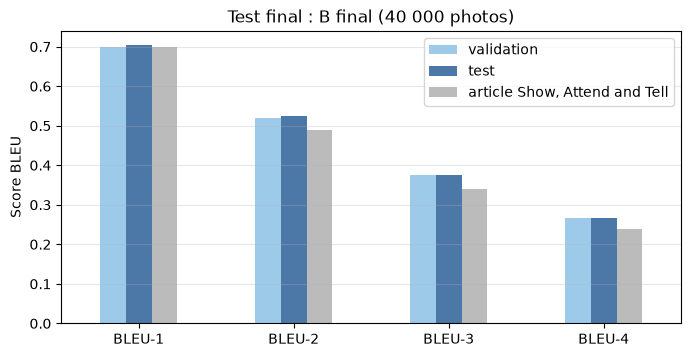

In [13]:
TEST = charger_features(ids_test, CNN_FINAL)
hyp_test, att_test = legender(FINAL, TEST)
resultats_test = pd.Series(bleu(hyp_test, ids_test), name="test")

comparaison = pd.DataFrame({
    "validation": FINAL["val"], "test": resultats_test,
    "article Show, Attend and Tell": {"BLEU-1": 0.70, "BLEU-2": 0.49, "BLEU-3": 0.34, "BLEU-4": 0.24},
})
display(comparaison.round(3))

ax = comparaison.plot.bar(figsize=(8, 3.8), rot=0, color=["#9ecae9", "#4C78A8", "#bbbbbb"])
ax.set_ylabel("Score BLEU")
ax.set_title(f"Test final : {NOM_FINAL}")
ax.grid(axis="y", alpha=0.3)
plt.show()

### Analyse : test final

- **Le test confirme la validation :** BLEU-1 de 0,705 contre 0,700 et BLEU-4 de **0,267** dans les deux cas. Le modèle généralise bien à des photos jamais vues, et le choix fait sur la validation ne l'a pas favorisé.
- **Notre modèle est légèrement au-dessus de l'article *Show, Attend and Tell*** sur les quatre scores (BLEU-4 de 0,267 contre 0,24), avec 40 000 photos d'entraînement contre environ 80 000 dans l'article.
- **Précaution :** le calcul n'est pas exactement celui de l'article (autres photos de test, autre découpage des mots, CNN plus récent). Les scores sont donc **du même ordre**, légèrement au-dessus, sans pouvoir conclure que notre modèle est meilleur.
- **À retenir :** avec un BLEU-1 de 0,705, environ **7 mots sur 10** de nos légendes se retrouvent dans les légendes humaines.

## 12. Étude de cas

### 12.1 Réussites et échecs

Pour chaque photo de test, nous calculons le BLEU-4 de sa légende (`sentence_bleu`). Nous affichons les 3 meilleures légendes, les 3 moins bonnes, et 3 photos prises au hasard pour avoir une idée du résultat habituel.

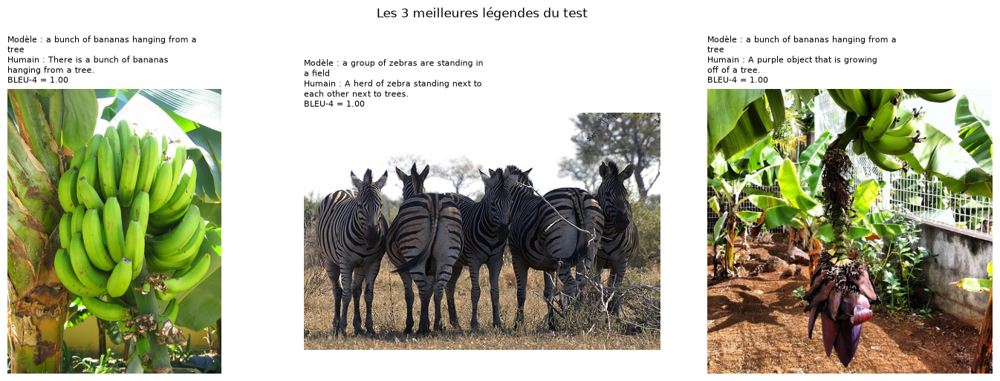

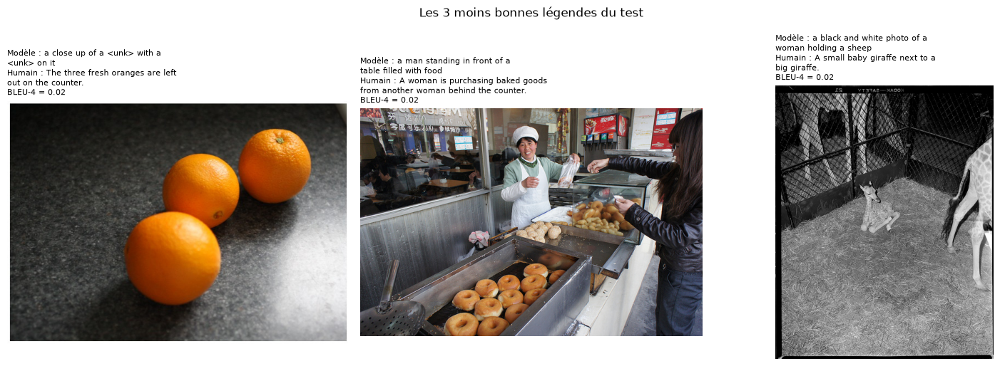

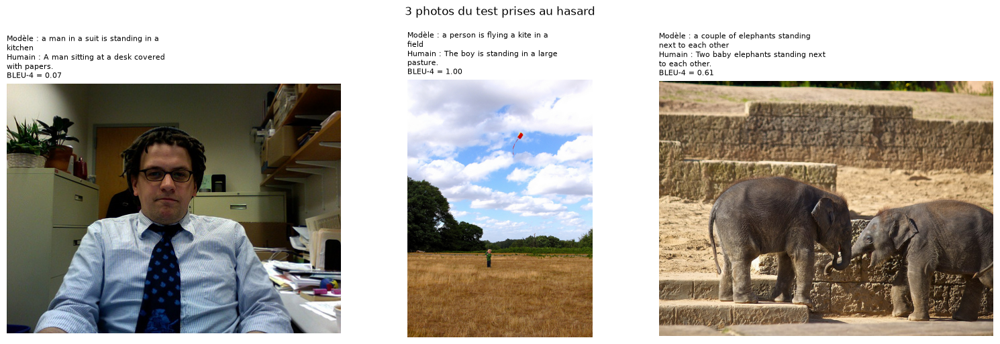

In [14]:
sm = SmoothingFunction().method1
scores_photo = np.array([sentence_bleu(references[i], h, smoothing_function=sm) for i, h in zip(ids_test, hyp_test)])
ordre = np.argsort(scores_photo)


def montrer(indices, titre):
    fig, axes = plt.subplots(1, len(indices), figsize=(5 * len(indices), 5.2))
    for ax, k in zip(axes, indices):
        ax.imshow(Image.open(IMAGES_DIR / nom_image(ids_test[k])).convert("RGB"))
        ax.set_title(textwrap.fill("Modèle : " + " ".join(hyp_test[k]), 42) + "\n"
                     + textwrap.fill("Humain : " + legendes_brutes[ids_test[k]][0], 42)
                     + f"\nBLEU-4 = {scores_photo[k]:.2f}", fontsize=8, loc="left")
        ax.axis("off")
    plt.suptitle(titre)
    plt.tight_layout()
    plt.show()


montrer(ordre[::-1][:3], "Les 3 meilleures légendes du test")
montrer(ordre[:3], "Les 3 moins bonnes légendes du test")
montrer(np.random.default_rng(SEED).choice(len(ids_test), 3, replace=False), "3 photos du test prises au hasard")

### 12.2 Où regarde le modèle ?

Pour chaque mot écrit, nous affichons les **poids d'attention** sur la photo : les zones claires sont celles que le modèle regardait pour écrire ce mot. La grille 8 × 8 est agrandie à la taille de la photo.

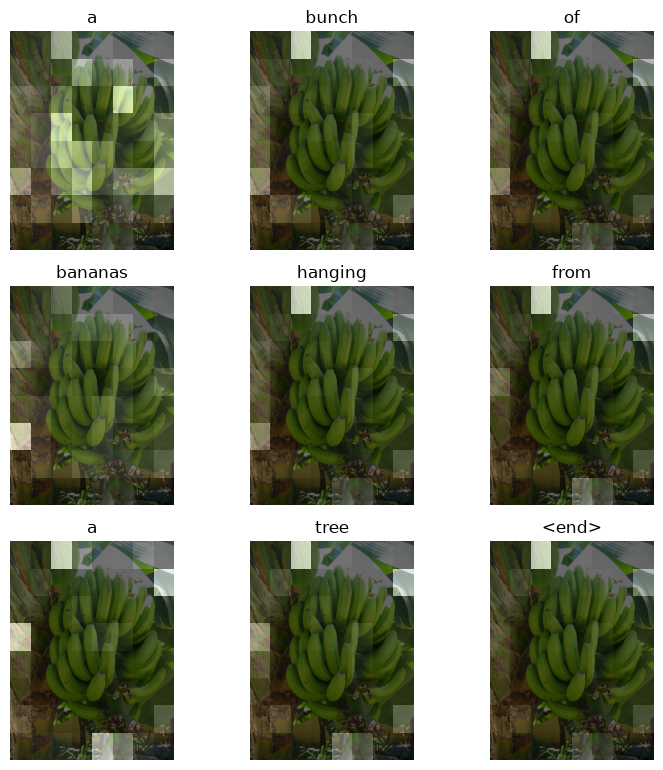

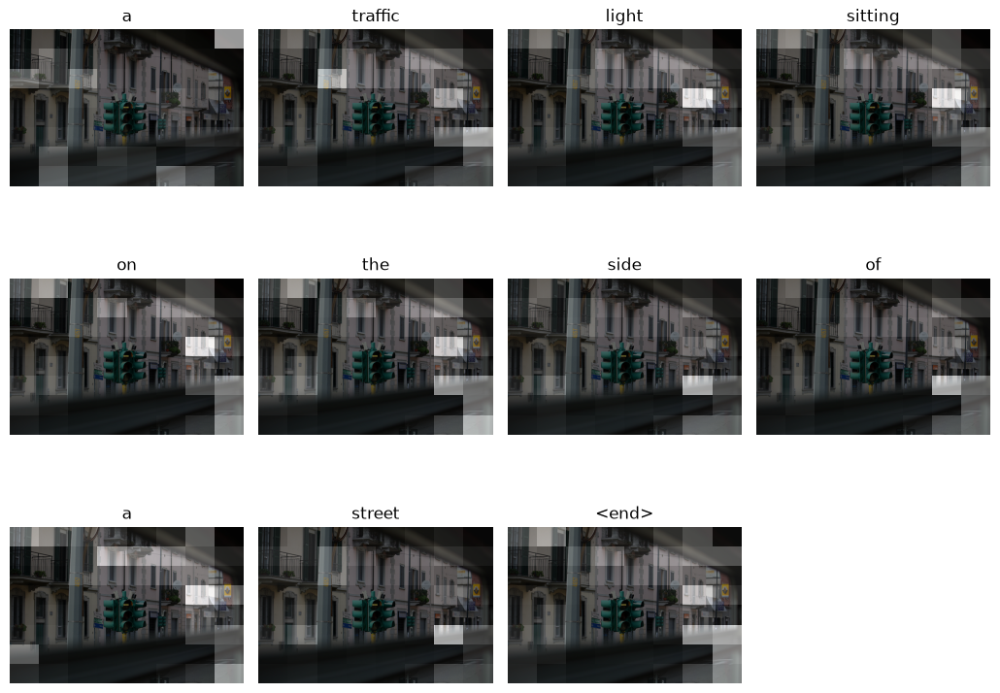

In [15]:
def plot_attention(k):
    image = np.array(Image.open(IMAGES_DIR / nom_image(ids_test[k])).convert("RGB"))
    mots = (hyp_test[k] + ["<end>"])[:MAX_LEN]
    grille = int(np.ceil(np.sqrt(len(mots))))         # grille carrée assez grande pour tous les mots
    fig = plt.figure(figsize=(2.6 * grille, 2.6 * grille))
    for l, mot in enumerate(mots):
        ax = fig.add_subplot(grille, grille, l + 1)
        img = ax.imshow(image)
        ax.imshow(att_test[k, l].reshape(8, 8), cmap="gray", alpha=0.6, extent=img.get_extent())
        ax.set_title(mot)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_attention(ordre[-1])
plot_attention(ordre[len(ordre) // 2])

### Analyse : étude de cas

**Les réussites (BLEU-4 = 1,00)** sont des scènes courantes de COCO : « a bunch of bananas hanging from a tree » (deux fois), « a group of zebras are standing in a field ». Sur la troisième photo, la légende humaine affichée parle d'un « objet violet », mais une autre des 5 légendes humaines correspond à celle du modèle : c'est tout l'intérêt d'avoir 5 références.

**Les échecs (BLEU-4 = 0,02)** montrent trois types d'erreur :

- **un objet sans mot assez probable :** pour trois oranges sur un fond uni, le modèle écrit « a close up of a `<unk>` with a `<unk>` on it ». Il ne trouve aucun mot assez probable et choisit le jeton réservé aux mots rares ;
- **une scène comprise mais des détails faux :** la vendeuse de beignets devient « a man standing in front of a table filled with food » ;
- **une photo inhabituelle :** des girafes en noir et blanc deviennent « a black and white photo of a woman holding a sheep ». Le style de la photo est reconnu, les animaux non.

**Les photos prises au hasard** donnent une idée du résultat habituel : le cerf-volant est parfait (1,00), les éléphants presque (0,61 : « a couple of elephants » au lieu de « two baby elephants », des synonymes que le BLEU ne reconnaît pas). L'homme à son bureau devient « a man in a suit is standing in a kitchen » (0,07) : la personne et le vêtement sont justes, le lieu est faux.

**Les cartes d'attention (12.2)** sont à lire avec prudence. Sur la photo des bananes, le premier mot regarde bien les bananes, puis les poids deviennent faibles et diffus. Sur le feu de circulation, l'attention se pose surtout sur des zones claires de la façade, alors que la légende est juste. Le modèle s'appuie donc beaucoup sur sa mémoire, qui contient le résumé de toute la photo depuis le premier mot.

**Bilan :** les scènes courantes sont très bien décrites. Les erreurs viennent surtout des objets rares et des photos inhabituelles, et le BLEU sous-estime parfois des légendes correctes à cause des synonymes.

## 13. Sauvegarde du modèle final

Le modèle final doit pouvoir être réutilisé **sans refaire l'entraînement**, notamment par le notebook `Test_Soutenance.ipynb`. Nous sauvegardons dans `livrable3_artifacts/` :

- les poids de l'encodeur et du décodeur ;
- un fichier `config_captioning.json` : la configuration (CNN, RNN, mémoire de départ, tailles), le vocabulaire, la longueur maximale des légendes et les scores du test ;
- quelques identifiants de photos de test, pour la répétition de la soutenance ;
- l'encodeur et le décodeur au format **`.keras`** (architecture et poids dans un seul fichier), vérifiés en section 13.1.

Le code du modèle est déjà enregistré dans `captioning_modele.py`.

In [16]:
FINAL["encoder"].save_weights(SORTIE_DIR / "encodeur.weights.h5")
FINAL["decoder"].save_weights(SORTIE_DIR / "decodeur.weights.h5")

config_sauvegarde = {
    "nom": NOM_FINAL,
    "modele": FINAL["config"],
    "vocab_size": VOCAB_SIZE,
    "max_len": MAX_LEN,
    "start_id": START_ID,
    "end_id": END_ID,
    "index_word": {str(k): v for k, v in tokenizer.index_word.items() if k < TOP_K},
    "bleu_test": {k: round(float(v), 4) for k, v in resultats_test.items()},
}
(SORTIE_DIR / "config_captioning.json").write_text(json.dumps(config_sauvegarde, ensure_ascii=False, indent=1))
(SORTIE_DIR / "ids_test.json").write_text(json.dumps(ids_test[:20]))
print("Modèle final sauvegardé dans :", SORTIE_DIR.resolve())

Modèle final sauvegardé dans : /home/ylies/projet/Projet/Livrable3/livrable3_artifacts


### 13.1 Format `.keras`

Les poids seuls ne suffisent pas : il faut aussi le code du modèle pour les recharger. Le format **`.keras`** enregistre l'architecture et les poids dans **un seul fichier**. Nous recréons le modèle final à partir de sa configuration, rechargeons ses poids, l'enregistrons au format `.keras`, puis vérifions que les modèles rechargés écrivent exactement les mêmes légendes.

In [17]:
import sys, json, importlib
from pathlib import Path
import numpy as np
from tensorflow import keras

sys.path.insert(0, ".")
import captioning_modele as cm
importlib.reload(cm)                       # dernière version du fichier (classes enregistrables en .keras)

SORTIE_DIR = Path("livrable3_artifacts")
cfg = json.loads((SORTIE_DIR / "config_captioning.json").read_text(encoding="utf-8"))

# 1. On recrée le modèle final et on recharge ses poids appris
encodeur, decodeur = cm.construire(cfg["modele"], cfg["vocab_size"])
encodeur.load_weights(SORTIE_DIR / "encodeur.weights.h5")
decodeur.load_weights(SORTIE_DIR / "decodeur.weights.h5")

# 2. Enregistrement au format .keras (architecture + poids dans un seul fichier)
encodeur.save(SORTIE_DIR / "encodeur.keras")
decodeur.save(SORTIE_DIR / "decodeur.keras")

# 3. Vérification : les modèles rechargés écrivent les mêmes légendes
enc2 = keras.models.load_model(SORTIE_DIR / "encodeur.keras")
dec2 = keras.models.load_model(SORTIE_DIR / "decodeur.keras")
f = np.random.rand(4, 64, cm.CNNS[cfg["modele"]["cnn"]][2]).astype("float32")
a = cm.generer(encodeur, decodeur, f, cfg["start_id"], cfg["max_len"])[0]
b = cm.generer(enc2, dec2, f, cfg["start_id"], cfg["max_len"])[0]
print("Fichiers .keras identiques au modèle :", (a == b).all())

Fichiers .keras identiques au modèle : True


## Conclusion

**Question étudiée :** peut-on améliorer l'architecture de captioning du workshop, et quels réglages donnent les légendes les plus fidèles sur des photos jamais vues ?

### Le chemin parcouru

| Étape | Modèle | Photos d'entraînement | BLEU-4 |
|---|---|---|---|
| Départ | A, réglages du workshop | 1 000 | 0,151 (validation) |
| Notre architecture | B, réglages du workshop | 1 000 | 0,165 (validation) |
| Après réglage | B, Dropout 0,5 | 1 000 | 0,175 (validation) |
| Plus de données | A et B à égalité | 20 000 | 0,254 / 0,253 (validation) |
| Modèle final | **B** | **40 000** | **0,267 (validation et test)** |

### Nos hypothèses

1. **Un CNN plus précis donne de meilleures légendes : confirmée.** Seul, il apporte tout le gain sur 1 000 photos (+0,015), B est devant A pour toutes les valeurs d'hyperparamètres testées, et il fait la différence à 40 000 photos.
2. **Une vue d'ensemble dès le premier mot aide le décodeur : partiellement confirmée.** Seule et sur 1 000 photos, la mémoire de départ n'améliore pas le score (+0,001) mais accélère l'apprentissage. Elle fait partie de l'architecture B qui l'emporte à 40 000 photos, sans que nous l'ayons mesurée seule à cette échelle.
3. **La quantité de données compte plus que les réglages : confirmée.** Passer de 1 000 à 20 000 photos apporte +0,08 à +0,09 de BLEU-4, bien plus que tous les réglages réunis. Il fallait 40 000 photos pour révéler l'avantage de B.

### Le modèle final

**Architecture B** : InceptionResNetV2 (gelé) + encodeur Dense 256 + attention de Bahdanau + LSTM 512 avec une mémoire de départ calculée depuis la photo ; Dropout 0,5, taux d'apprentissage 0,001, lots de 64 ; entraîné sur 40 000 photos. Sur le test, il obtient un **BLEU-4 de 0,267** et un **BLEU-1 de 0,705**, du même ordre que l'article de référence et légèrement au-dessus. Il est sauvegardé dans `livrable3_artifacts/` (poids et format `.keras`) et réutilisé sans réentraînement par `Test_Soutenance.ipynb`.

### Limites

- Chaque modèle n'a été entraîné qu'avec **une seule graine** : les petits écarts peuvent venir du hasard.
- Les hyperparamètres ont été réglés **un par un**, sur 1 000 photos.
- Nous avons utilisé **40 000 photos sur 82 783**.
- Les **mots rares** et les **photos inhabituelles** restent mal décrits, et le BLEU ne reconnaît pas les synonymes.
- Le test avait déjà été mesuré une fois avec le modèle A à 20 000 photos ; aucun choix n'en a dépendu.

### Pistes d'amélioration

- Utiliser **toutes les photos de COCO** : B progressait encore entre 20 000 et 40 000 photos.
- Réentraîner les dernières couches du CNN (*fine-tuning*) avec un faible taux d'apprentissage.
- Écrire la légende avec un **beam search**, pour éviter les répétitions.
- Répéter chaque entraînement avec **plusieurs graines** pour confirmer les petits écarts.
- À plus long terme, tester un décodeur de type **Transformer**.